# Preparación de datos · mosto natural y sintético

Adaptación del notebook preparing_data de la rama recalibration del repositorio anterior, conservando sus matrices, recuentos y comparación de horarios. No calibra ni cambia datos o configuraciones.

**Fuentes locales existentes:** naturales depurados en data/compatibility/chemistry/observations_cleaned_lab004_009.csv; sintéticos en data/original/synthetic/mosto_sintetico_vl3.xlsx; reloj clocks.csv, calendario y logs en data/original/natural/process_logs. Los sintéticos se normalizan en memoria con las funciones de conversión necesarias del cargador histórico, incorporadas en este notebook. No se copia un CSV combinado ni módulos del repositorio anterior. El Excel original natural permanece intacto y separado del depurado.

Se conservan LAB004–009 y MS007–016, siete variables (biomasa viable, YAN, G, F, G+F, densidad y etanol) y las dos matrices de temperatura. No se completan faltantes. G+F requiere G y F en la misma muestra. La conversión correcta de 30pg/célula es **0.03 g/L por millón de células/mL**; un documento antiguo decía0.003, pero su código usa0.03.

Los horarios propuestos, calendario y cruce1040 se muestran como referencias diferentes, no como varias nutriciones. Las activaciones de bomba no se convierten automáticamente en dosis. Las exclusiones y correcciones Oculyze se verifican sobre el CSV depurado existente, sin aplicarlas al Excel original.

**Importante:** visualizar observaciones en preparing_data no demuestra qué filas entraron a cada optimización. La auditoría al final diferencia el prototipo temprano, theta_full histórico y la recalibración posterior.

Procedencia: rama recalibration, commit 16a8500ac3ca79260e0ba59f9657f82724a2f2de; archivo fermentation_model/laboratory_2026/notebooks/calibration/preparing_data.source.ipynb; SHA256 SOURCE original f1c95911749ac3ff957ae0f1c5719ab1dbe4c7b95241d1990a4f3e15ec146ca0.


La sección 9 incorpora la revisión de química, cobertura y horarios de LAB013–015 a partir de sus fuentes originales.

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display

get_ipython().run_line_magic('matplotlib', 'inline')
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'src/wine_fermentation').is_dir())
DATA_PATH = ROOT / 'data/compatibility/chemistry/observations_cleaned_lab004_009.csv'
input_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
LABS = tuple(f'LAB{i:03d}' for i in range(4, 10))
BIOMASS_COLUMN = 'X_viable_kg_m3'

import numpy as np
from typing import Iterable
SECONDARY_METABOLITE_COLUMNS = {
    "PAN_mg_l": ["PAN", "Y15 PAN"],
    "NH4_mg_l": ["AMMONIA", "Y15 Amonio"],
    "pyruvic_acid": ["PYRUVIC ACID", "PYRUVIC_ACID", "Y15 Piruvic"],
    "pyruvic_acid_2": ["PYRUVIC ACID2"],
    "acetaldehyde": ["ACETALDEHIDO", "Y15 Acetaldehido"],
    "acetic_acid": ["Y15 Acetico", "ACETIC ACID", "ACETIC_ACID"],
}

AROMA_COLUMNS = {
    "benzyl_alcohol_total": ["bencil_alcohol_total", "benzyl_alcohol_total"],
    "benzaldehyde_total": ["benzaldehido_total", "benzaldehyde_total"],
    "ethyl_decanoate_total": ["decanoato_de_etilo_total", "ethyl_decanoate_total"],
    "hexyl_acetate_total": ["hexil_acetate_total", "hexyl_acetate_total"],
    "isoamyl_acetate_total": ["isoamil_acetate_total", "isoamyl_acetate_total"],
    "ethyl_octanoate_total": ["octanoate_de_etilo_total", "ethyl_octanoate_total"],
    "phenylethyl_acetate_total": ["phenylethylacetate_total", "phenylethyl_acetate_total"],
    "ethyl_acetate_total": ["Ethyl_Acetate_total", "ethyl_acetate_total"],
}

ETHANOL_DENSITY_G_ML = 0.78924

ETHANOL_G_L_PER_PERCENT_VV = 10.0 * ETHANOL_DENSITY_G_ML

CELL_MASS_PG_PER_CELL = 30.0

CELL_MASS_G_PER_CELL = CELL_MASS_PG_PER_CELL * 1e-12

MILLION_CELLS_ML_TO_KG_M3 = CELL_MASS_PG_PER_CELL * 1e-3

MG_L_TO_KG_M3 = 1e-3

def _clean_columns(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df.columns = [str(col).strip() for col in df.columns]
    return df

def _numeric(df: pd.DataFrame, column: str) -> pd.Series:
    if column not in df.columns:
        return pd.Series(np.nan, index=df.index, dtype=float)
    return pd.to_numeric(df[column], errors="coerce")

def _first_available_numeric(df: pd.DataFrame, columns: Iterable[str]) -> pd.Series:
    values = pd.Series(np.nan, index=df.index, dtype=float)
    for column in columns:
        if column not in df.columns:
            continue
        candidate = pd.to_numeric(df[column], errors="coerce")
        values = values.where(values.notna(), candidate)
    return values

def _ethanol_observation(raw: pd.DataFrame) -> tuple[pd.Series, pd.Series, pd.Series, pd.Series]:
    primary = _numeric(raw, "ETANOL")
    primary = primary.where(primary >= 0.0)

    fallback = _first_available_numeric(raw, ["Cf Alcolyzer Real (% v/v)", "Cf Alcolyzer (% v/v)"])
    fallback = fallback.where(fallback > 0.0)

    primary_values = primary.dropna()
    primary_is_g_l = bool(primary_values.gt(25.0).any())

    percent_vv = primary.where(primary.notna(), fallback)
    e_g_l = percent_vv * ETHANOL_G_L_PER_PERCENT_VV
    unit = pd.Series("", index=raw.index, dtype=object)
    source = pd.Series("", index=raw.index, dtype=object)

    if primary_is_g_l:
        e_g_l = primary.where(primary.notna(), fallback * ETHANOL_G_L_PER_PERCENT_VV)
        percent_vv = (primary / ETHANOL_G_L_PER_PERCENT_VV).where(
            primary.notna(),
            fallback,
        )
        unit = unit.mask(primary.notna(), "g_l")
    else:
        unit = unit.mask(primary.notna(), "percent_vv")

    unit = unit.mask(primary.isna() & fallback.notna(), "percent_vv")
    source = source.mask(primary.notna(), "ETANOL")
    source = source.mask(primary.isna() & fallback.notna(), "ALCOLYZER_FALLBACK")
    return percent_vv, e_g_l, source, unit

def normalize_must_sheet(raw: pd.DataFrame, medium: str, batch: str, source_file: Path) -> pd.DataFrame:
    raw = _clean_columns(raw)
    out = pd.DataFrame(index=raw.index)
    out["medium"] = str(medium)
    out["batch"] = str(batch)
    out["source_file"] = str(source_file.name)
    out["sample_id"] = raw["ID"].astype(str) if "ID" in raw.columns else ""

    out["time_h"] = _first_available_numeric(raw, ["time", "t", "Horas"])
    out["temperature_c"] = _first_available_numeric(
        raw,
        ["temperature", "temperatura", "Temperatura_operacional_columna_Temperatura", "Temperatura"],
    )
    out["density"] = _first_available_numeric(raw, ["densidad", "Densidad"])
    out["brix"] = _first_available_numeric(raw, ["Brix"])
    out["DO_mg_l"] = _first_available_numeric(
        raw,
        ["DO", "Dissolved Oxygen", "Dissolved oxygen", "Oxigeno disuelto", "Oxígeno disuelto"],
    )
    out.loc[out["DO_mg_l"] < 0.0, "DO_mg_l"] = np.nan

    out["X_viable_mcells_ml"] = _first_available_numeric(raw, ["C_viable", "Viability"])
    out["X_total_mcells_ml"] = _first_available_numeric(raw, ["Oculyze Concentration", "C_total"])
    viable_for_dead = out["X_viable_mcells_ml"].interpolate(limit_direction="both")
    out["X_dead_direct_mcells_ml"] = (out["X_total_mcells_ml"] - out["X_viable_mcells_ml"]).clip(lower=0.0)
    out["X_dead_mcells_ml"] = (out["X_total_mcells_ml"] - viable_for_dead).clip(lower=0.0)
    out["X_dead_inferred"] = (
        out["X_total_mcells_ml"].notna()
        & out["X_viable_mcells_ml"].isna()
        & viable_for_dead.notna()
    )

    out["X_viable_kg_m3"] = out["X_viable_mcells_ml"] * MILLION_CELLS_ML_TO_KG_M3
    out["X_total_kg_m3"] = out["X_total_mcells_ml"] * MILLION_CELLS_ML_TO_KG_M3
    out["X_dead_kg_m3"] = out["X_dead_mcells_ml"] * MILLION_CELLS_ML_TO_KG_M3

    out["G_g_l"] = _first_available_numeric(raw, ["GLUCOSE", "GLUCOSE-320"])
    out["F_g_l"] = _first_available_numeric(raw, ["FRUCTOSE", "FRUCTOSE_inferida"])
    out["S_GF_g_l"] = out["G_g_l"] + out["F_g_l"]
    out.loc[out["G_g_l"].isna() | out["F_g_l"].isna(), "S_GF_g_l"] = np.nan
    out["S_Y15_g_l"] = _first_available_numeric(raw, ["Y15 Glucosa-Fructosa", "GLU-FRU-320"])
    out["S_observed_g_l"] = out["S_GF_g_l"].where(out["S_GF_g_l"].notna(), out["S_Y15_g_l"])

    out["YAN_mg_l"] = _first_available_numeric(raw, ["YAN"])
    out["N_kg_m3"] = out["YAN_mg_l"] * MG_L_TO_KG_M3
    out["N_pulse_mg_l"] = _first_available_numeric(raw, ["pulso_nut"]).fillna(0.0)
    out["N_pulse_kg_m3"] = out["N_pulse_mg_l"] * MG_L_TO_KG_M3
    out["PAN_mg_l"] = _first_available_numeric(raw, SECONDARY_METABOLITE_COLUMNS["PAN_mg_l"])
    out["NH4_mg_l"] = _first_available_numeric(raw, SECONDARY_METABOLITE_COLUMNS["NH4_mg_l"])
    out["PAN_kg_m3"] = out["PAN_mg_l"] * MG_L_TO_KG_M3
    out["NH4_kg_m3"] = out["NH4_mg_l"] * MG_L_TO_KG_M3
    out["YAN_components_mg_l"] = out["PAN_mg_l"] + out["NH4_mg_l"]
    out.loc[out["PAN_mg_l"].isna() | out["NH4_mg_l"].isna(), "YAN_components_mg_l"] = np.nan

    for normalized_column, raw_columns in SECONDARY_METABOLITE_COLUMNS.items():
        if normalized_column in {"PAN_mg_l", "NH4_mg_l"}:
            continue
        out[normalized_column] = _first_available_numeric(raw, raw_columns)

    out["glycerol_g_l"] = _first_available_numeric(raw, ["GLYCEROL"])
    (
        out["ethanol_percent_vv"],
        out["E_g_l"],
        out["ethanol_source"],
        out["ethanol_unit"],
    ) = _ethanol_observation(raw)

    for normalized_column, raw_columns in AROMA_COLUMNS.items():
        out[normalized_column] = _first_available_numeric(raw, raw_columns)

    for column in ["Condicion", "Condición", "Replica", "Réplica", "Variedad", "Levadura", "Adicion"]:
        if column in raw.columns:
            safe_column = (
                column.replace("ó", "o")
                .replace("é", "e")
                .replace("í", "i")
                .replace("á", "a")
                .replace("ú", "u")
            )
            out[safe_column] = raw[column]

    out = out.dropna(subset=["time_h"]).drop_duplicates(["medium", "batch", "time_h"], keep="first")
    out = out.sort_values("time_h").reset_index(drop=True)
    return out
SYNTHETIC_BOOK=ROOT/'data/original/synthetic/mosto_sintetico_vl3.xlsx'
synthetic_hash=hashlib.sha256(SYNTHETIC_BOOK.read_bytes()).hexdigest()
synthetic_frames=[normalize_must_sheet(pd.read_excel(SYNTHETIC_BOOK,sheet_name=f'MS{i:03d}'),
    'synthetic',f'MS{i:03d}',SYNTHETIC_BOOK) for i in range(7,17)]
raw=pd.concat([pd.read_csv(DATA_PATH),*synthetic_frames],ignore_index=True)

biomass = raw.loc[raw.medium.eq('natural') & raw.batch.isin(LABS),
                  ['batch', 'sample_id', 'time_h', BIOMASS_COLUMN]].copy()
for column in ['time_h', BIOMASS_COLUMN]:
    biomass[column] = pd.to_numeric(biomass[column], errors='coerce')
# Trazabilidad de la depuración ya aplicada a las fuentes; no es un filtro del notebook.
exclusion_specs = (
    ('LAB004', 'ING26-LAB004-10', 115.0, 'Caída aislada con recuperación posterior'),
    ('LAB005', 'ING26-LAB005-10', 115.0, 'Caída aislada con recuperación posterior'),
    ('LAB006', 'ING26-LAB006-09', 115.0, 'Caída aislada con recuperación posterior'),
    ('LAB007', 'ING26-LAB007-L-13', 160.0, 'Última muestra: caída abrupta; exclusión confirmada'),
    ('LAB008', 'ING26-LAB008-L-13', 160.0, 'Última muestra: caída abrupta; exclusión confirmada'),
    ('LAB009', 'ING26-LAB009-L-12', 160.0, 'Última muestra: caída abrupta; exclusión confirmada'),
)
biomass_fields = ['X_viable_mcells_ml', 'X_total_mcells_ml', 'X_dead_direct_mcells_ml',
                 'X_dead_mcells_ml', 'X_viable_kg_m3', 'X_total_kg_m3', 'X_dead_kg_m3']
removal_rows = []
for lab, sample_id, time_h, reason in exclusion_specs:
    match = (raw.medium.eq('natural') & raw.batch.eq(lab) & raw.sample_id.eq(sample_id)
             & raw.time_h.sub(time_h).abs().lt(1e-6))
    assert match.sum() == 1, (lab, sample_id, time_h)
    assert raw.loc[match, biomass_fields].isna().all().all()
    removal_rows.append({'batch':lab, 'sample_id':sample_id, 'time_h':time_h,
                         'estado':'Oculyze eliminado de la fuente', 'motivo':reason})
removed_oculyze = pd.DataFrame(removal_rows)
biomass = biomass.dropna(subset=['time_h', BIOMASS_COLUMN]).sort_values(['batch', 'time_h'])
assert len(removed_oculyze) == 6 and len(biomass) == 70
# Las tres correcciones manuales siguen presentes.
for lab, expected in [('LAB004', 1.044), ('LAB005', 1.5576), ('LAB006', 0.9195)]:
    point = biomass.loc[biomass.batch.eq(lab) & biomass.sample_id.eq(f'ING26-{lab}-04')]
    assert len(point) == 1 and abs(point.iloc[0][BIOMASS_COLUMN]-expected) < 1e-12
print('Mediciones Oculyze eliminadas de la fuente (otras variables conservadas):')
display(removed_oculyze)
assert tuple(sorted(biomass.batch.unique())) == LABS
assert not biomass.duplicated(['batch', 'time_h']).any()
print('Fuente:', DATA_PATH.relative_to(ROOT))
print('Muestras por LAB:', biomass.groupby('batch').size().to_dict())
# Referencia temporal: el mismo t0 archivado para estas series históricas.
import re
CALENDAR_PATH = ROOT / 'data/original/natural/process_logs/Fernanda Folch.ics'
CLOCK_PATH = ROOT / 'data/compatibility/chemistry/clocks.csv'
nutrition_input_hashes = {p:hashlib.sha256(p.read_bytes()).hexdigest() for p in (CALENDAR_PATH,CLOCK_PATH)}
clocks = pd.read_csv(CLOCK_PATH,usecols=['batch','t0']).drop_duplicates()
clocks = clocks.loc[clocks.batch.isin(LABS)].set_index('batch')
assert clocks.index.is_unique and set(clocks.index)==set(LABS)
calendar_text = re.sub(r'\r?\n[ \t]','',CALENDAR_PATH.read_text(encoding='utf-8-sig'))
nutrition_rows = []
for event in calendar_text.split('BEGIN:VEVENT')[1:]:
    event = event.split('END:VEVENT')[0]
    fields = dict(line.split(':',1) for line in event.splitlines() if ':' in line)
    if 'Pulso nutricional 2' not in fields.get('SUMMARY',''):
        continue
    match = re.search(r'LAB00[4-9]',event)
    if match is None:
        continue
    lab = match.group()
    event_utc = pd.to_datetime(fields['DTSTART'],format='%Y%m%dT%H%M%SZ',utc=True)
    t0_local = pd.Timestamp(clocks.loc[lab,'t0']).tz_localize('America/Santiago')
    nutrition_rows.append({'LAB':lab,'hora_calendario_local':event_utc.tz_convert('America/Santiago').isoformat(),
        't_nutricion_h':(event_utc-t0_local).total_seconds()/3600,
        'fuente':'Calendario operativo · pulso 2'})
nutrition = pd.DataFrame(nutrition_rows).sort_values('LAB').reset_index(drop=True)
assert tuple(nutrition.LAB)==LABS
nutrition_times = nutrition.set_index('LAB').t_nutricion_h.to_dict()
display(nutrition)

# Selección de ambas matrices y variables relevantes: solo observaciones disponibles.
SYNTHETIC_LABS = tuple(f'MS{i:03d}' for i in range(7, 17))
MATRICES = {'natural': LABS, 'synthetic': SYNTHETIC_LABS}
selected = raw.loc[(raw.medium.eq('natural') & raw.batch.isin(LABS))
                   | (raw.medium.eq('synthetic') & raw.batch.isin(SYNTHETIC_LABS))].copy()
VARIABLES = (
    ('X_viable_kg_m3', 'Biomasa viable', 'Biomasa viable [g/L]'),
    ('YAN_mg_l', 'Nitrógeno asimilable (YAN)', 'YAN [mg N/L]'),
    ('G_g_l', 'Glucosa', 'Glucosa [g/L]'),
    ('F_g_l', 'Fructosa', 'Fructosa [g/L]'),
    ('GF_g_l', 'Azúcar total: glucosa + fructosa', 'G+F [g/L]'),
    ('density', 'Densidad', 'Densidad [kg/m³; equivalente a g/L]'),
    ('E_g_l', 'Etanol', 'Etanol [g/L]'),
)
for column in ['time_h', 'N_pulse_mg_l', 'S_GF_g_l'] + [v[0] for v in VARIABLES if v[0] != 'GF_g_l']:
    selected[column] = pd.to_numeric(selected[column], errors='coerce')
selected['GF_g_l'] = selected['G_g_l'] + selected['F_g_l']
assert selected['GF_g_l'].isna().equals(selected['S_GF_g_l'].isna())
assert selected['GF_g_l'].sub(selected['S_GF_g_l']).dropna().abs().lt(1e-9).all()
assert selected.time_h.notna().all()
assert not selected.duplicated(['medium', 'batch', 'time_h']).any()
assert len(selected) == 181  # 85 filas naturales, 96 sintéticas; incluye filas de pulsos.
for medium, labs in MATRICES.items():
    assert set(selected.loc[selected.medium.eq(medium), 'batch']) == set(labs)
synthetic_nutrition = selected.loc[selected.medium.eq('synthetic') & selected.N_pulse_mg_l.gt(0),
                                   ['batch', 'sample_id', 'time_h', 'N_pulse_mg_l']].copy()
assert tuple(sorted(synthetic_nutrition.batch.unique())) == SYNTHETIC_LABS
print('Pulsos de N en sintéticos: tabla normalizada (dosis en mg N/L).')
display(synthetic_nutrition.reset_index(drop=True))
coverage = selected.groupby(['medium', 'batch'])[[v[0] for v in VARIABLES]].count()
coverage.columns = [v[1] for v in VARIABLES]
print('Cantidad de mediciones disponibles por experimento y variable:')
display(coverage)
plot_audit = []


Mediciones Oculyze eliminadas de la fuente (otras variables conservadas):


,batch,sample_id,time_h,estado,motivo
0,LAB004,ING26-LAB004-10,115.0,Oculyze eliminado de la fuente,Caída aislada con recuperación posterior
1,LAB005,ING26-LAB005-10,115.0,Oculyze eliminado de la fuente,Caída aislada con recuperación posterior
2,LAB006,ING26-LAB006-09,115.0,Oculyze eliminado de la fuente,Caída aislada con recuperación posterior
3,LAB007,ING26-LAB007-L-13,160.0,Oculyze eliminado de la fuente,Última muestra: caída abrupta; exclusión confi...
4,LAB008,ING26-LAB008-L-13,160.0,Oculyze eliminado de la fuente,Última muestra: caída abrupta; exclusión confi...
5,LAB009,ING26-LAB009-L-12,160.0,Oculyze eliminado de la fuente,Última muestra: caída abrupta; exclusión confi...


Fuente: data\compatibility\chemistry\observations_cleaned_lab004_009.csv
Muestras por LAB: {'LAB004': 11, 'LAB005': 11, 'LAB006': 13, 'LAB007': 12, 'LAB008': 12, 'LAB009': 11}


,LAB,hora_calendario_local,t_nutricion_h,fuente
0,LAB004,2026-04-08T16:30:00-04:00,51.50,Calendario operativo · pulso 2
1,LAB005,2026-04-08T16:30:00-04:00,51.50,Calendario operativo · pulso 2
2,LAB006,2026-04-09T16:30:00-04:00,75.50,Calendario operativo · pulso 2
3,LAB007,2026-04-19T12:45:00-04:00,44.75,Calendario operativo · pulso 2
4,LAB008,2026-04-19T12:45:00-04:00,44.75,Calendario operativo · pulso 2
5,LAB009,2026-04-19T12:45:00-04:00,44.75,Calendario operativo · pulso 2


Pulsos de N en sintéticos: tabla normalizada (dosis en mg N/L).


,batch,sample_id,time_h,N_pulse_mg_l
0,MS007,MS007-N,24.0,100.0
1,MS008,MS008-N,96.0,100.0
2,MS009,MS009-N,24.0,100.0
3,MS010,MS010-N,24.0,100.0
4,MS011,MS011-N,96.0,100.0
5,MS012,MS012-N,96.0,100.0
6,MS013,MS013-N,72.0,100.0
7,MS014,MS014-N,72.0,100.0
8,MS015,MS015-N,72.0,100.0
9,MS016,MS015-N,72.0,100.0


Cantidad de mediciones disponibles por experimento y variable:


Biomasa viable  Nitrógeno asimilable (YAN)  ...  Densidad  Etanol
medium    batch                                               ...                  
natural   LAB004              11                          13  ...        13       5
          LAB005              11                          13  ...        13       5
          LAB006              13                          15  ...        15       5
          LAB007              12                          13  ...        13       6
          LAB008              12                          13  ...        13       6
          LAB009              11                          12  ...        12       5
synthetic MS007                8                           9  ...         9       4
          MS008                8                           9  ...         9       4
          MS009                8                           9  ...         9       4
          MS010                8                           8  ...         9       4
          MS011                8                           8  ...         9       4
          MS012                8                           8  ...         9       4
          MS013                7                           8  ...         8       4
          MS014                7                           8  ...         8       4
          MS015                7                           8  ...         8       4
          MS016                7                           8  ...         8       4

[16 rows x 7 columns]

In [2]:
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

plt.style.use('seaborn-v0_8-whitegrid')

def density_crossing_for_lab(lab, target=1040.):
    samples = selected.loc[selected.medium.eq('natural') & selected.batch.eq(lab),
                           ['sample_id', 'time_h', 'density']].dropna().sort_values('time_h')
    candidates = []
    for i in range(len(samples)):
        left = samples.iloc[i]
        if abs(left.density-target) <= 1e-9:
            candidates.append((float(left.time_h), left, left))
        if i+1 < len(samples):
            right = samples.iloc[i+1]
            if (left.density-target)*(right.density-target) < 0:
                t = left.time_h+(target-left.density)*(right.time_h-left.time_h)/(right.density-left.density)
                candidates.append((float(t), left, right))
    assert candidates, f'Sin cruce de densidad {target}: {lab}'
    t, left, right = min(candidates, key=lambda value: abs(value[0]-nutrition_times[lab]))
    assert left.time_h <= t <= right.time_h
    return {'LAB':lab, 'calendario_h':nutrition_times[lab], 'cruce_1040_h':t,
            'cruce_menos_calendario_h':t-nutrition_times[lab],
            'muestra_izquierda':left.sample_id, 'muestra_derecha':right.sample_id,
            'intervalo_desde_h':float(left.time_h), 'intervalo_hasta_h':float(right.time_h),
            'ancho_intervalo_h':float(right.time_h-left.time_h)}

density_crossings = pd.DataFrame([density_crossing_for_lab(lab) for lab in LABS])
density_times = density_crossings.set_index('LAB').cruce_1040_h.to_dict()
print('Calendario frente a cruce de densidad 1040: referencias de tiempo, no confirmación de dosificación.')
display(density_crossings.round(3))


# Horarios elegidos por el usuario: se añade 1 h a la propuesta previa en LAB004–008; LAB009 no cambia.
# Se conservan como propuesta del análisis: no se reescriben eventos ni dosis de las fuentes.
proposed_anchor_specs = (
    ('LAB004', 'ING26-LAB004-06', 1.5),
    ('LAB005', 'ING26-LAB005-06', 1.5),
    ('LAB006', 'ING26-LAB006-08', 2.0),
    ('LAB007', 'ING26-LAB007-L-06', 1.5),
    ('LAB008', 'ING26-LAB008-L-06', 1.5),
)
proposed_rows = []
for lab, sample_id, delay_h in proposed_anchor_specs:
    observations = selected.loc[selected.medium.eq('natural') & selected.batch.eq(lab)
                                & selected.YAN_mg_l.notna()].sort_values('time_h')
    anchor = observations.loc[observations.sample_id.eq(sample_id)]
    assert len(anchor) == 1
    anchor = anchor.iloc[0]
    following = observations.loc[observations.time_h.gt(anchor.time_h)].iloc[0]
    pulse_h = float(anchor.time_h + delay_h)
    assert anchor.time_h < pulse_h < following.time_h
    assert following.YAN_mg_l > anchor.YAN_mg_l
    proposed_rows.append({'LAB':lab, 'muestra_ancla':sample_id, 'ancla_h':float(anchor.time_h),
        'YAN_ancla_mg_L':float(anchor.YAN_mg_l), 'demora_h':delay_h, 'pulso_propuesto_h':pulse_h,
        'muestra_siguiente':following.sample_id, 'siguiente_h':float(following.time_h),
        'YAN_siguiente_mg_L':float(following.YAN_mg_l), 'criterio':'Muestra baja + demora indicada por el usuario'})
proposed_rows.append({'LAB':'LAB009', 'muestra_ancla':None, 'ancla_h':None,
    'YAN_ancla_mg_L':None, 'demora_h':None, 'pulso_propuesto_h':density_times['LAB009'],
    'muestra_siguiente':None, 'siguiente_h':None, 'YAN_siguiente_mg_L':None,
    'criterio':'Cruce de densidad 1040, según indicación del usuario'})
proposed_pulses = pd.DataFrame(proposed_rows)
proposed_pulses['fecha_hora_local'] = [
    (pd.Timestamp(clocks.loc[row.LAB, 't0']).tz_localize('America/Santiago')
     + pd.Timedelta(hours=row.pulso_propuesto_h)).isoformat()
    for row in proposed_pulses.itertuples()]
proposed_times = proposed_pulses.set_index('LAB').pulso_propuesto_h.to_dict()
assert tuple(proposed_pulses.LAB) == LABS
print('Pulsos propuestos por criterio del usuario; no son registros de ejecución confirmada:')
display(proposed_pulses)

def plot_matrix(column, label, ylabel, medium):
    labs = MATRICES[medium]
    group = selected.loc[selected.medium.eq(medium)]
    is_natural = medium == 'natural'
    compare_timing = is_natural and column == 'YAN_mg_l'
    figsize = (14, 8) if is_natural else (19, 8)
    fig, axes = plt.subplots(2, 3 if is_natural else 5, figsize=figsize,
                             sharex=True, sharey=True, layout='constrained')
    values = selected[column].dropna().to_numpy(float)
    assert len(values) and np.isfinite(values).all()
    lower, upper = float(values.min()), float(values.max())
    span = max(upper-lower, abs(upper)*0.05, 1e-6)
    # Margen mínimo bajo cero cuando corresponde: permite ver líneas en cero.
    limits = ((lower-0.05*span, upper+0.08*span) if column == 'density'
              else (min(0., lower)-0.02*span, upper+0.08*span))
    xmax = float(group.time_h.max())
    counts = {}
    for ax, lab, color in zip(axes.flat, labs, plt.get_cmap('tab10').colors):
        samples = group.loc[group.batch.eq(lab) & group[column].notna()].sort_values('time_h')
        assert samples.time_h.is_unique and len(samples) > 0
        line, = ax.plot(samples.time_h, samples[column], color=color,
                        marker='o', markersize=4.5, linewidth=1.6, zorder=3)
        assert np.array_equal(line.get_xdata(), samples.time_h.to_numpy())
        assert np.array_equal(line.get_ydata(), samples[column].to_numpy())
        counts[lab] = len(samples)
        times = ([nutrition_times[lab] if compare_timing else proposed_times[lab]] if is_natural else
                 synthetic_nutrition.loc[synthetic_nutrition.batch.eq(lab), 'time_h'].tolist())
        reference_color = '#007F5F' if is_natural and not compare_timing else '#555555'
        reference_style = '-.' if is_natural and not compare_timing else '--'
        for t_nut in times:
            ax.axvline(t_nut, color=reference_color, linestyle=reference_style, linewidth=1.3 if is_natural and not compare_timing else 1.1, zorder=2)
            ax.text(t_nut+0.015*xmax, 0.96, (f'Cal.: {t_nut:g} h' if compare_timing else f'Pulso: {t_nut:.2f} h' if is_natural else f'N: {t_nut:g} h'),
                    transform=ax.get_xaxis_transform(), va='top', ha='left', fontsize=7,
                    bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=1.5))
        if compare_timing:
            crossing = density_times[lab]
            crossing_line = ax.axvline(crossing, color='#C000A0', linestyle=':', linewidth=1.7, zorder=2)
            assert np.allclose(crossing_line.get_xdata(), [crossing, crossing])
            ax.text(crossing+0.015*xmax, 0.86, f'1040: {crossing:.2f} h',
                    transform=ax.get_xaxis_transform(), va='top', ha='left', fontsize=7,
                    color='#A00080',
                    bbox=dict(facecolor='white', edgecolor='none', alpha=0.85, pad=1.5))
            proposal = proposed_times[lab]
            proposal_line = ax.axvline(proposal, color='#007F5F', linestyle='-.', linewidth=1.3, zorder=2.1)
            assert np.allclose(proposal_line.get_xdata(), [proposal, proposal])
            ax.text(proposal+0.015*xmax, 0.76, f'Pulso: {proposal:.2f} h',
                    transform=ax.get_xaxis_transform(), va='top', ha='left', fontsize=7,
                    color='#007F5F',
                    bbox=dict(facecolor='white', edgecolor='none', alpha=0.85, pad=1.5))
        ax.set_title(f'{lab} · n={len(samples)}', fontsize=11)
        ax.set_xlim(-0.02*xmax, 1.02*xmax)
        ax.set_ylim(*limits)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
        ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
        ax.tick_params(labelbottom=True, labelleft=True, labelsize=9)
        ax.grid(alpha=0.3)
    matrix_label = 'Mosto natural · LAB004–009' if is_natural else 'Mosto sintético · MS007–016'
    pulse_label = ('Nutrición 2 · calendario operativo' if compare_timing
                   else 'Pulso propuesto · criterio del usuario' if is_natural
                   else 'Pulso N · tabla normalizada')
    fig.suptitle(f'{label} · {matrix_label}', fontsize=14, y=0.995)
    fig.supxlabel('Tiempo histórico [h]')
    fig.supylabel(ylabel)
    handles = [Line2D([], [], color='#333333', marker='o', lw=1.6, label='Muestras disponibles'),
               Line2D([], [], color='#555555' if compare_timing or not is_natural else '#007F5F',
                      ls='--' if compare_timing or not is_natural else '-.',
                      lw=1.3 if is_natural and not compare_timing else 1.1, label=pulse_label)]
    if compare_timing:
        handles.append(Line2D([], [], color='#C000A0', ls=':', lw=1.7, label='Cruce de densidad 1040 · estimado'))
        handles.append(Line2D([], [], color='#007F5F', ls='-.', lw=1.3, label='Pulso propuesto · criterio del usuario'))
    fig.get_layout_engine().set(rect=(0, 0, 1, 0.90))
    fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 0.965),
               ncol=2, frameon=False, fontsize=9)
    plot_audit.append({'variable':column, 'medium':medium, 'counts':counts, 'ylim':limits,
                       'n_panels':len(axes.flat), 'compares_density_1040':compare_timing, 'uses_proposed_pulse':is_natural})
    plt.show()
    plt.close(fig)


Calendario frente a cruce de densidad 1040: referencias de tiempo, no confirmación de dosificación.


,LAB,calendario_h,cruce_1040_h,cruce_menos_calendario_h,muestra_izquierda,muestra_derecha,intervalo_desde_h,intervalo_hasta_h,ancho_intervalo_h
0,LAB004,51.50,56.092,4.592,ING26-LAB004-05,ING26-LAB004-06,50.0,67.0,17.0
1,LAB005,51.50,55.087,3.587,ING26-LAB005-05,ING26-LAB005-06,50.0,67.0,17.0
2,LAB006,75.50,74.000,-1.500,ING26-LAB006-07,ING26-LAB006-07,74.0,74.0,0.0
3,LAB007,44.75,56.246,11.496,ING26-LAB007-L-05,ING26-LAB007-L-06,48.0,64.0,16.0
4,LAB008,44.75,56.750,12.000,ING26-LAB008-L-05,ING26-LAB008-L-06,48.0,64.0,16.0
5,LAB009,44.75,41.846,-2.904,ING26-LAB009-L-04,ING26-LAB009-L-05,40.0,48.0,8.0


Pulsos propuestos por criterio del usuario; no son registros de ejecución confirmada:


,LAB,muestra_ancla,ancla_h,YAN_ancla_mg_L,demora_h,pulso_propuesto_h,muestra_siguiente,siguiente_h,YAN_siguiente_mg_L,criterio,fecha_hora_local
0,LAB004,ING26-LAB004-06,67.0,5.0,1.5,68.500000,ING26-LAB004-07,74.0,35.86,Muestra baja + demora indicada por el usuario,2026-04-09T09:30:00-04:00
1,LAB005,ING26-LAB005-06,67.0,12.0,1.5,68.500000,ING26-LAB005-07,74.0,35.68,Muestra baja + demora indicada por el usuario,2026-04-09T09:30:00-04:00
2,LAB006,ING26-LAB006-08,98.0,0.0,2.0,100.000000,ING26-LAB006-09,115.0,58.00,Muestra baja + demora indicada por el usuario,2026-04-10T17:00:00-04:00
3,LAB007,ING26-LAB007-L-06,64.0,2.0,1.5,65.500000,ING26-LAB007-L-07,72.0,47.78,Muestra baja + demora indicada por el usuario,2026-04-20T09:30:00-04:00
4,LAB008,ING26-LAB008-L-06,64.0,11.0,1.5,65.500000,ING26-LAB008-L-07,72.0,47.78,Muestra baja + demora indicada por el usuario,2026-04-20T09:30:00-04:00
5,LAB009,None,NaN,NaN,NaN,41.846154,None,NaN,NaN,"Cruce de densidad 1040, según indicación del u...",2026-04-19T09:50:46.153846154-04:00


## 1. Biomasa viable

Las seis mediciones Oculyze descartadas ya están ausentes de la fuente. Se conservan las muestras corregidas de LAB004–006.

Primero mosto natural; después mosto sintético.

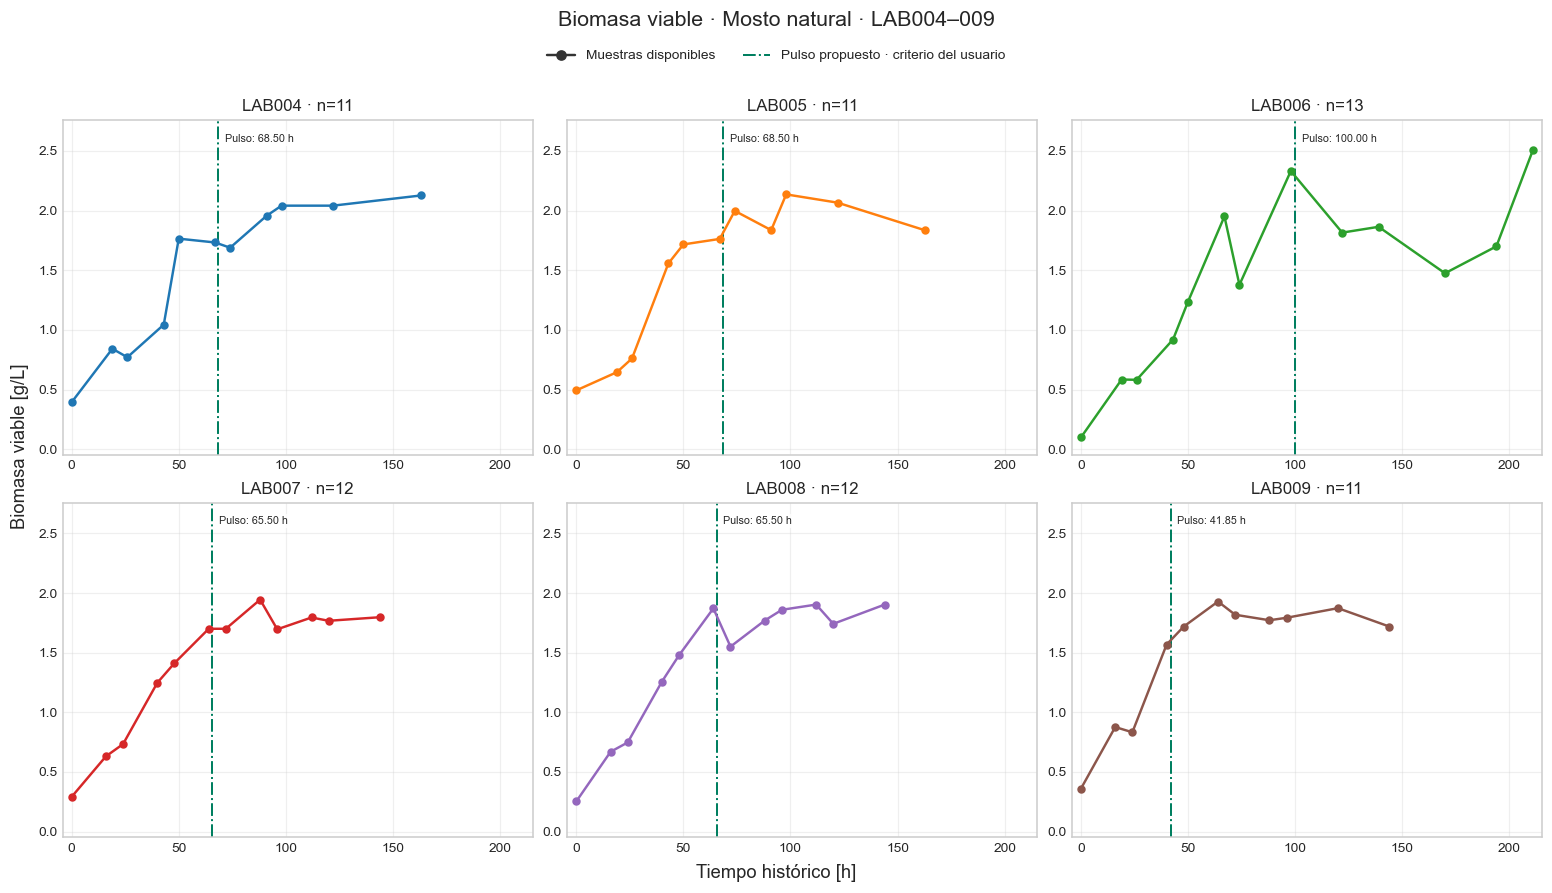

In [3]:
plot_matrix('X_viable_kg_m3', 'Biomasa viable', 'Biomasa viable [g/L]', 'natural')

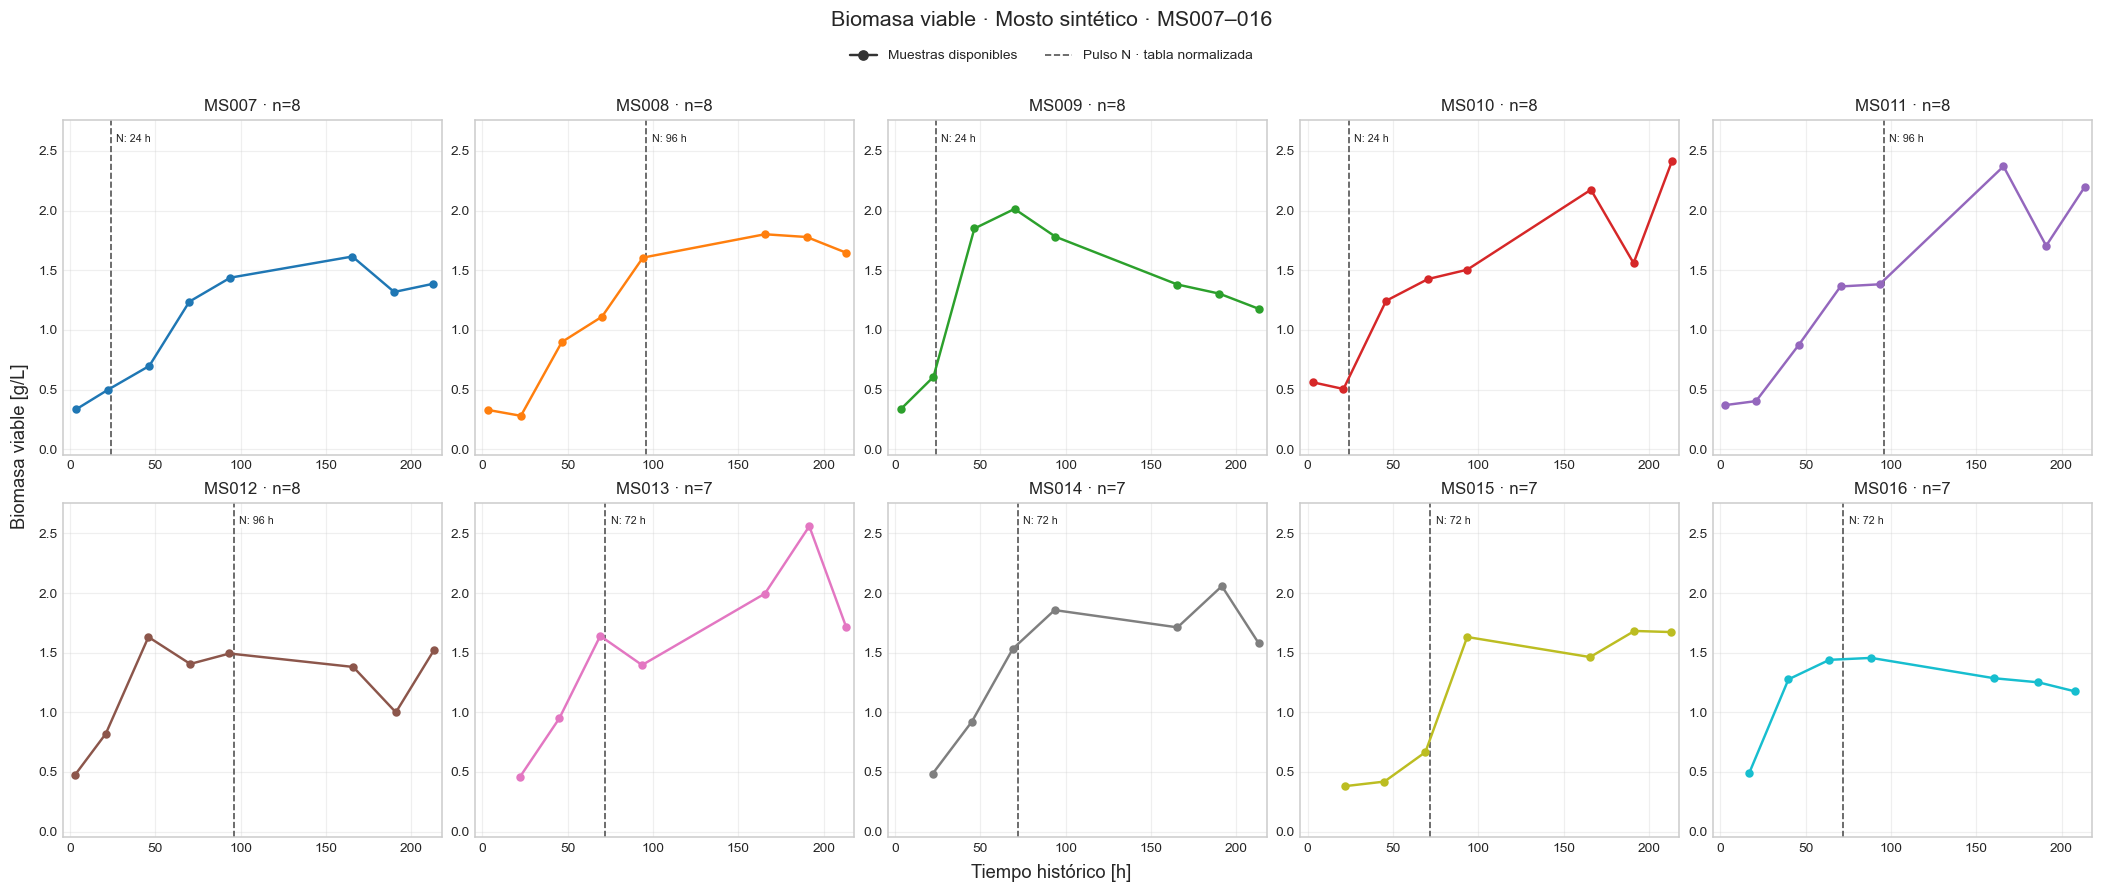

In [4]:
plot_matrix('X_viable_kg_m3', 'Biomasa viable', 'Biomasa viable [g/L]', 'synthetic')

## 2. Nitrógeno asimilable (YAN)

Se muestran concentraciones medidas; las dosis de los pulsos no se dibujan como mediciones de YAN. Primero mosto natural; después mosto sintético.

En **YAN natural** se comparan calendario (gris discontinuo), cruce de densidad 1040 (magenta punteado) y pulso propuesto por el usuario (verde de trazo y punto). LAB004/005: muestra de 67 h + 1.5 h = 68.5 h; LAB006: muestra de 98 h + 2 h = 100 h; LAB007/008: muestra de 64 h + 1.5 h = 65.5 h; LAB009: cruce 1040 sin cambios. Se ha sumado una hora a la propuesta anterior de LAB004–008. Las anclas y siguientes muestras se comprueban contra el CSV y se documentan con fecha/hora local.

Los decimales no representan precisión experimental. Los horarios verdes son supuestos explícitos, no registros históricos confirmados; en LAB009 verde y magenta coinciden. Las otras figuras naturales usan el horario propuesto; las sintéticas mantienen las entradas archivadas. No se cambian datos, dosis ni calibraciones.


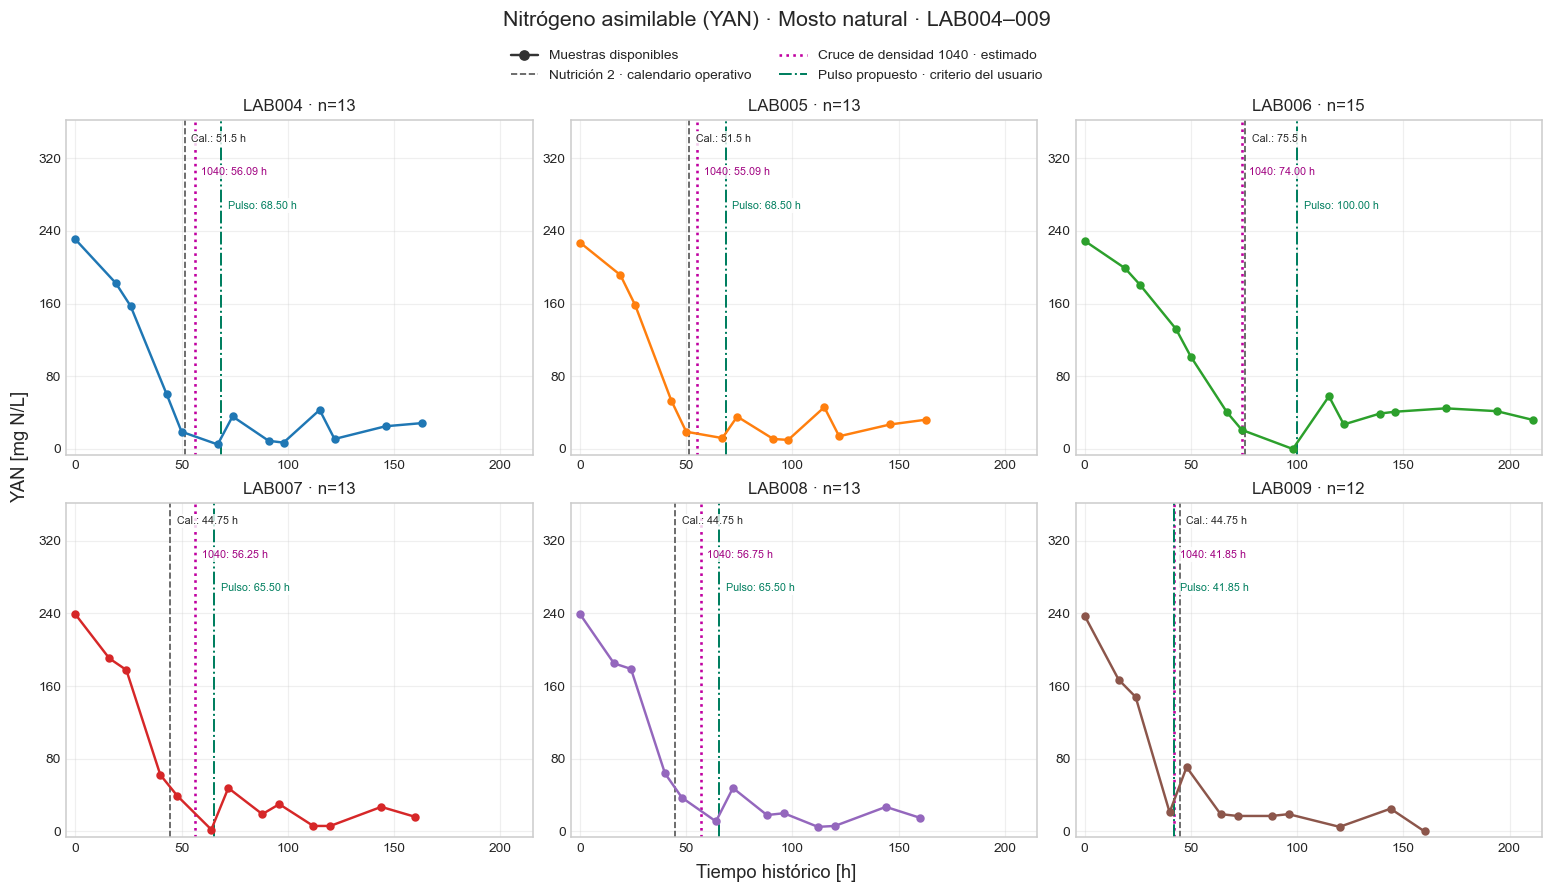

In [5]:
plot_matrix('YAN_mg_l', 'Nitrógeno asimilable (YAN)', 'YAN [mg N/L]', 'natural')

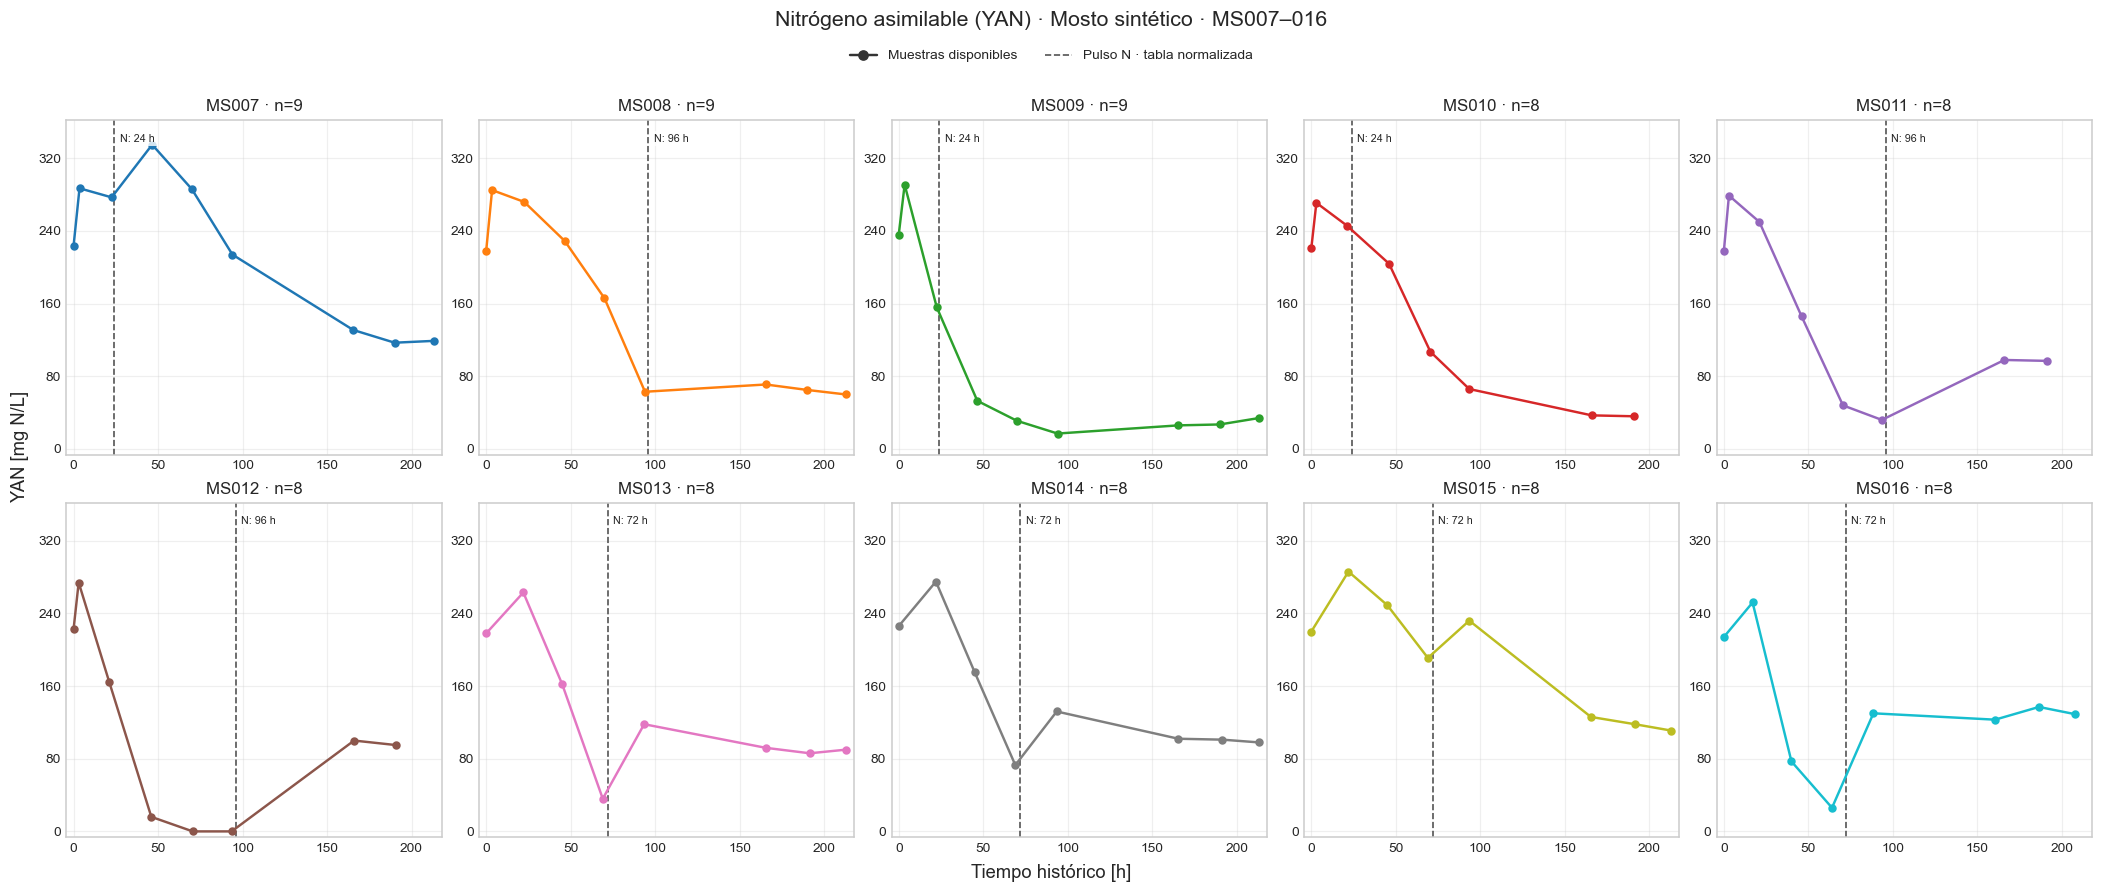

In [6]:
plot_matrix('YAN_mg_l', 'Nitrógeno asimilable (YAN)', 'YAN [mg N/L]', 'synthetic')

## 3. Glucosa



Primero mosto natural; después mosto sintético.

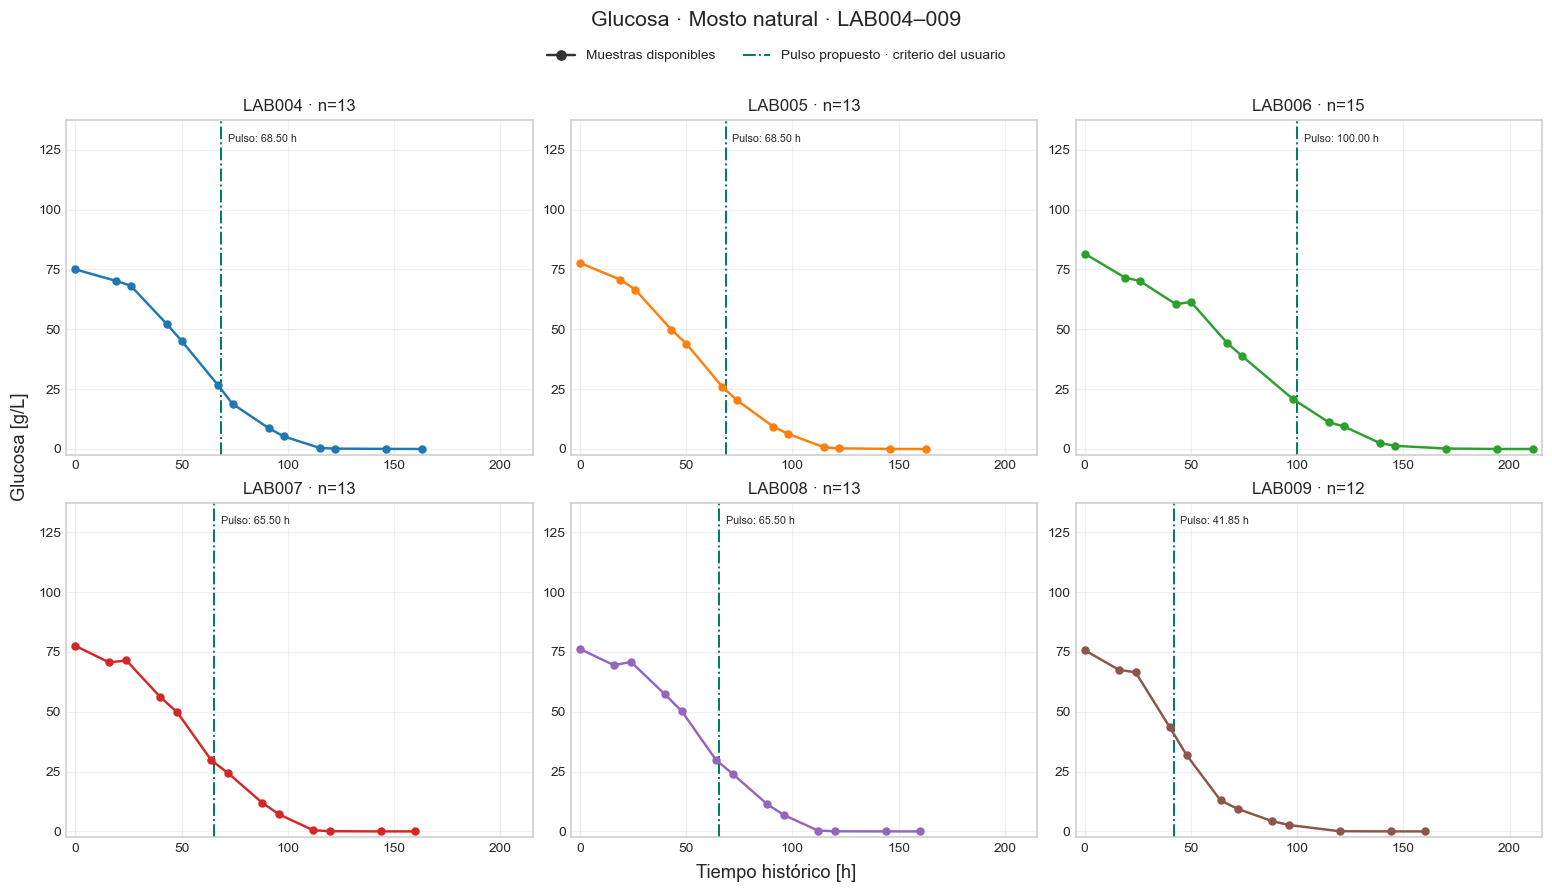

In [7]:
plot_matrix('G_g_l', 'Glucosa', 'Glucosa [g/L]', 'natural')

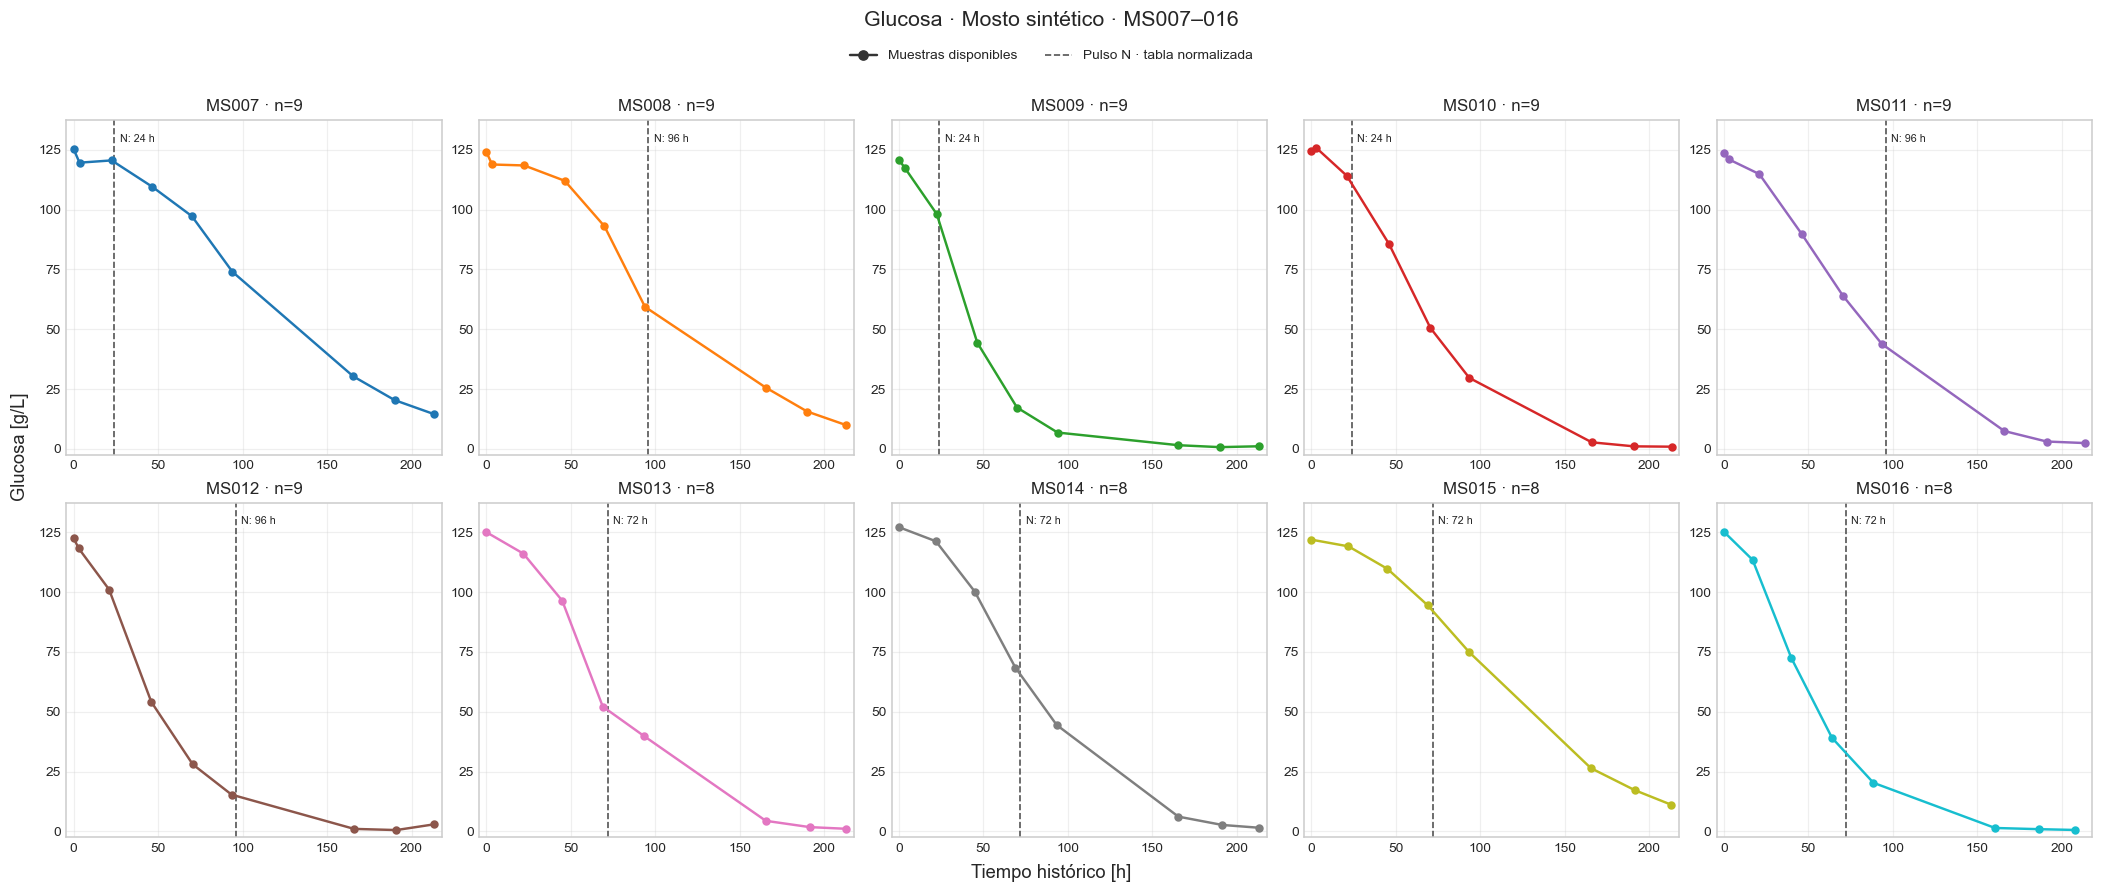

In [8]:
plot_matrix('G_g_l', 'Glucosa', 'Glucosa [g/L]', 'synthetic')

## 4. Fructosa



Primero mosto natural; después mosto sintético.

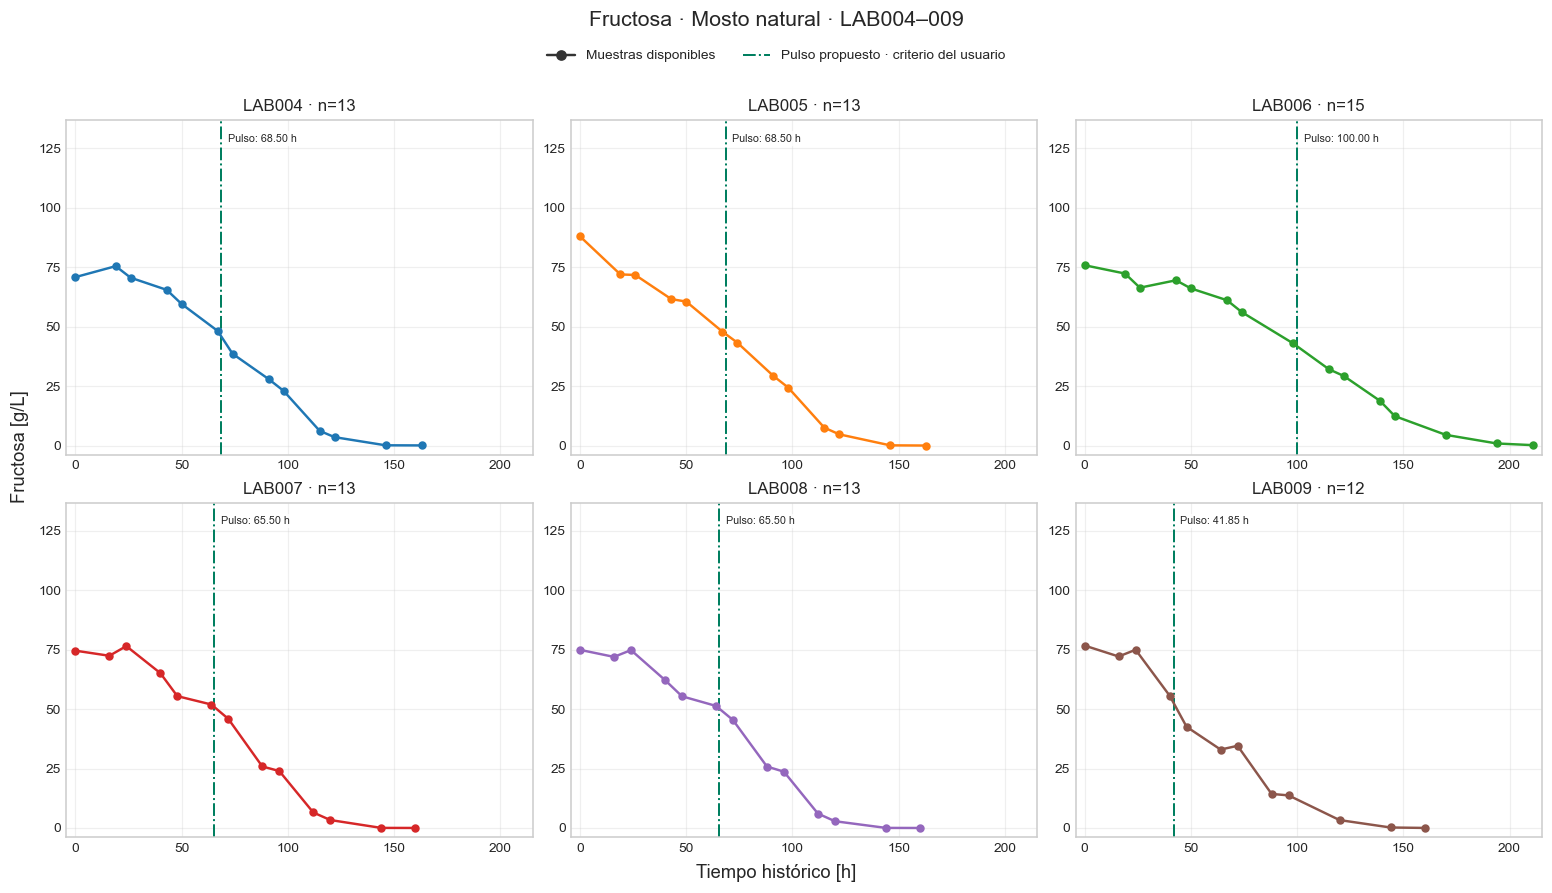

In [9]:
plot_matrix('F_g_l', 'Fructosa', 'Fructosa [g/L]', 'natural')

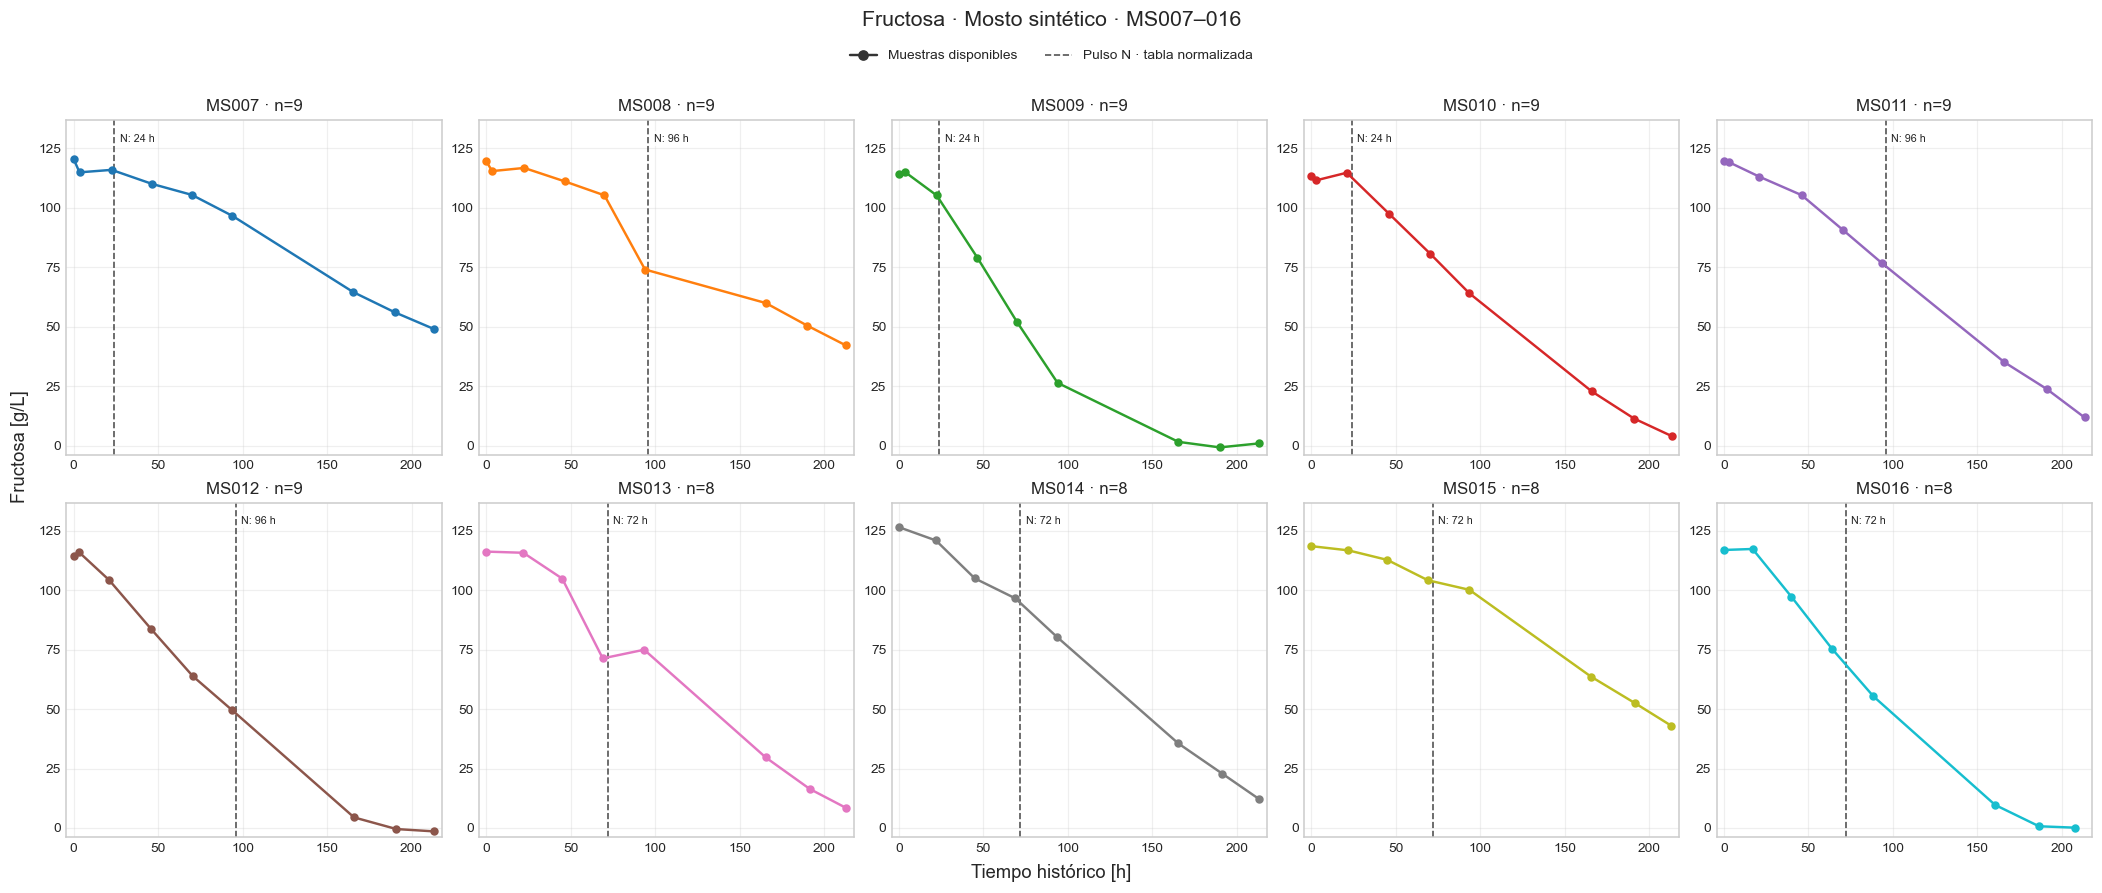

In [10]:
plot_matrix('F_g_l', 'Fructosa', 'Fructosa [g/L]', 'synthetic')

## 5. Azúcar total: glucosa + fructosa

La suma G+F usa únicamente pares medidos en la misma muestra. No se infiere azúcar desde densidad.

Primero mosto natural; después mosto sintético.

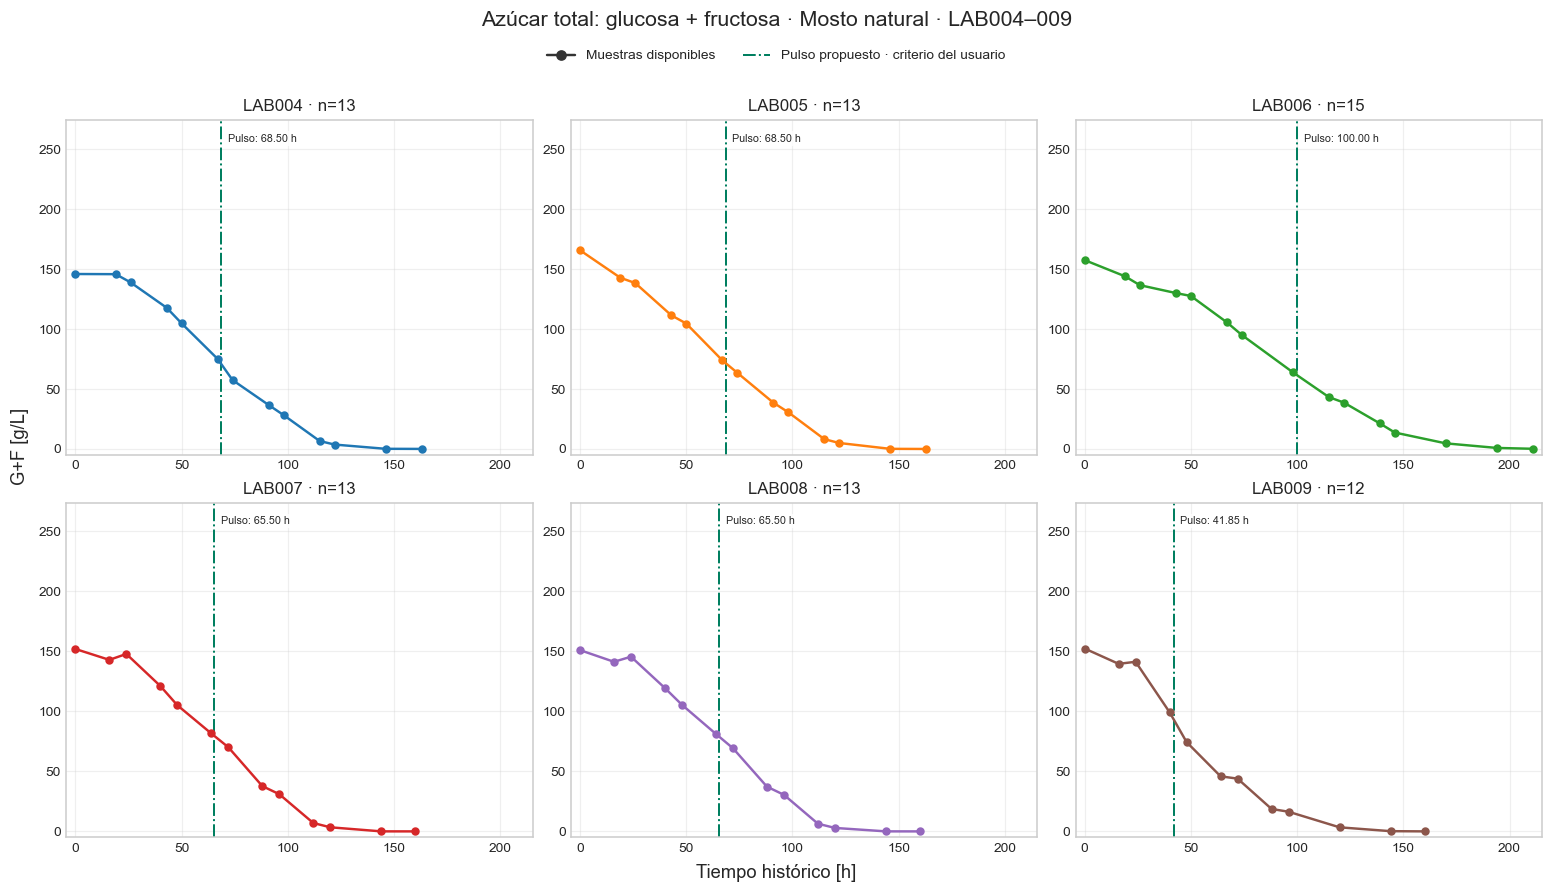

In [11]:
plot_matrix('GF_g_l', 'Azúcar total: glucosa + fructosa', 'G+F [g/L]', 'natural')

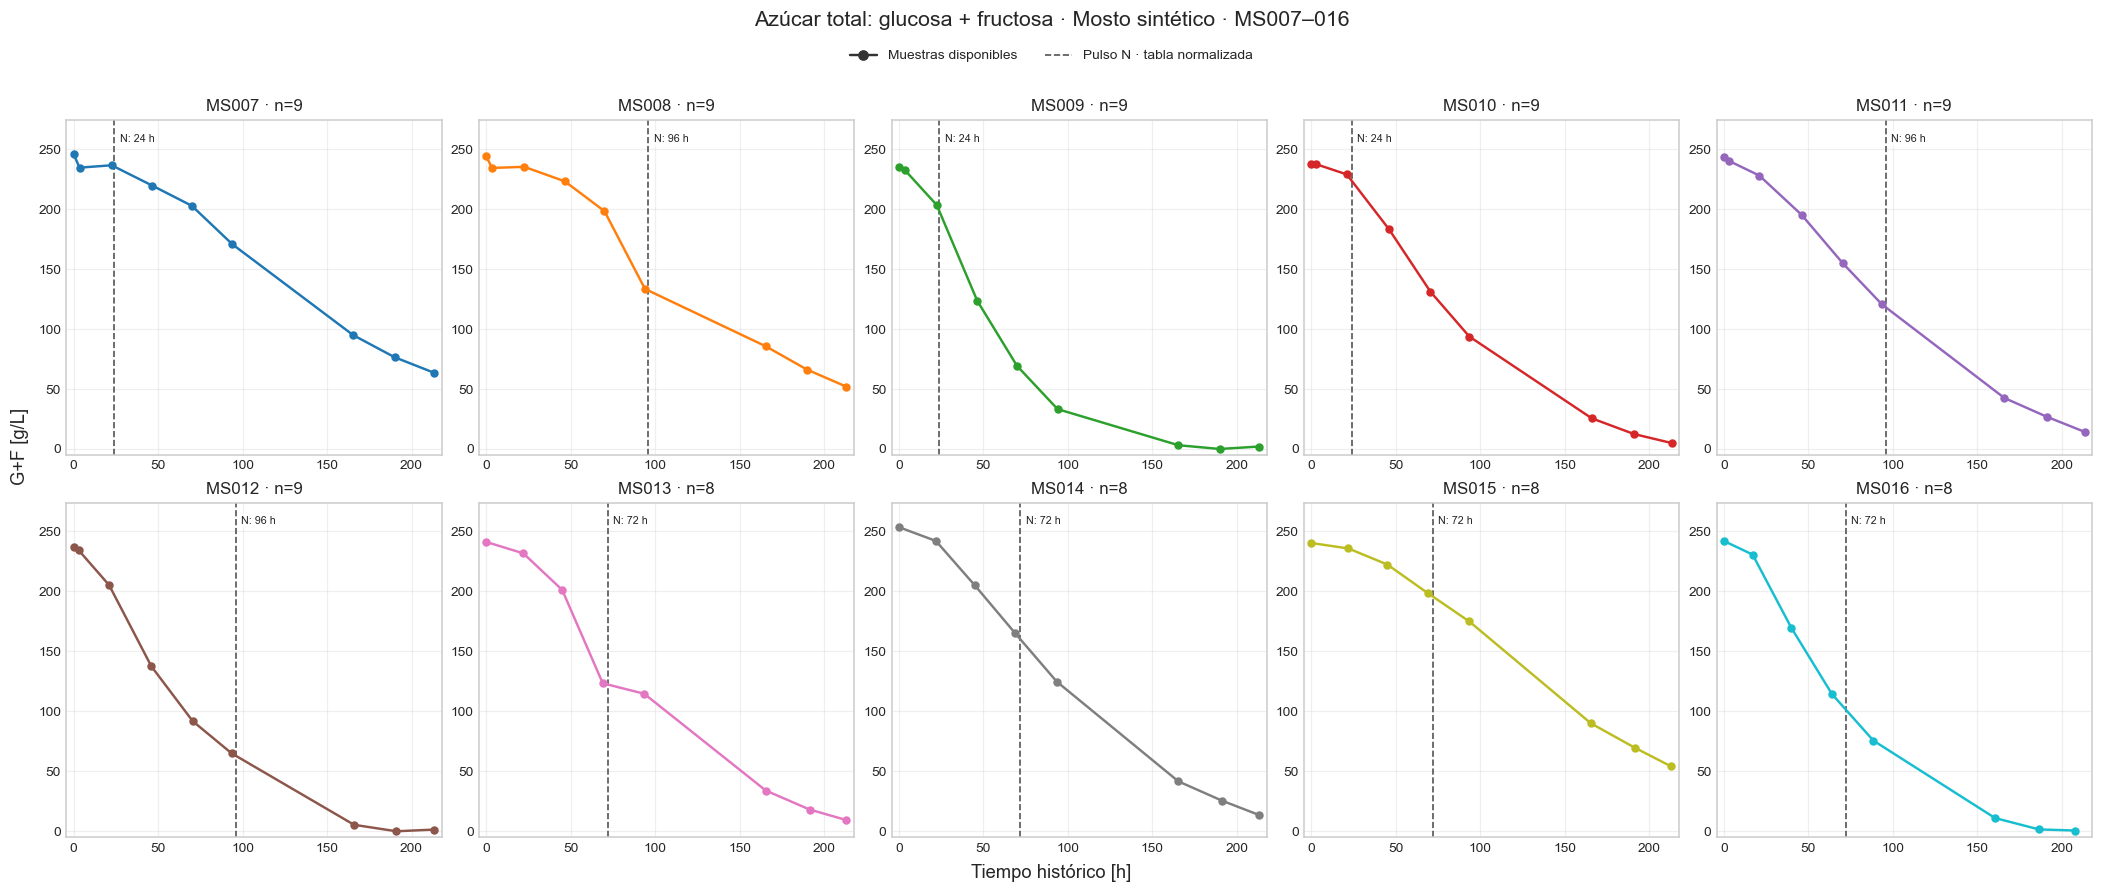

In [12]:
plot_matrix('GF_g_l', 'Azúcar total: glucosa + fructosa', 'G+F [g/L]', 'synthetic')

## 6. Densidad



Primero mosto natural; después mosto sintético.

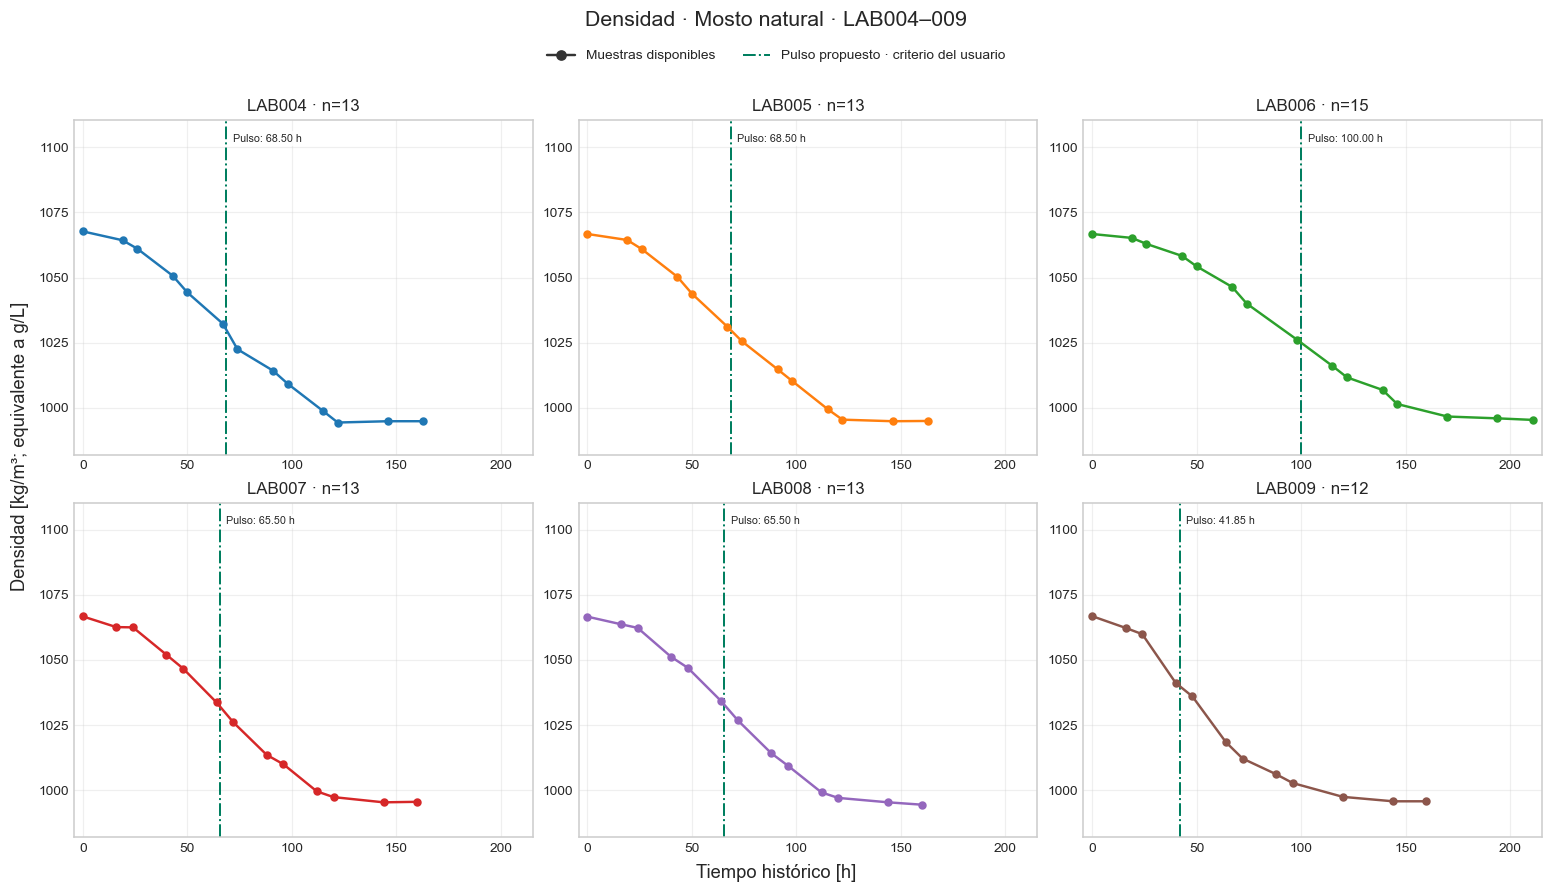

In [13]:
plot_matrix('density', 'Densidad', 'Densidad [kg/m³; equivalente a g/L]', 'natural')

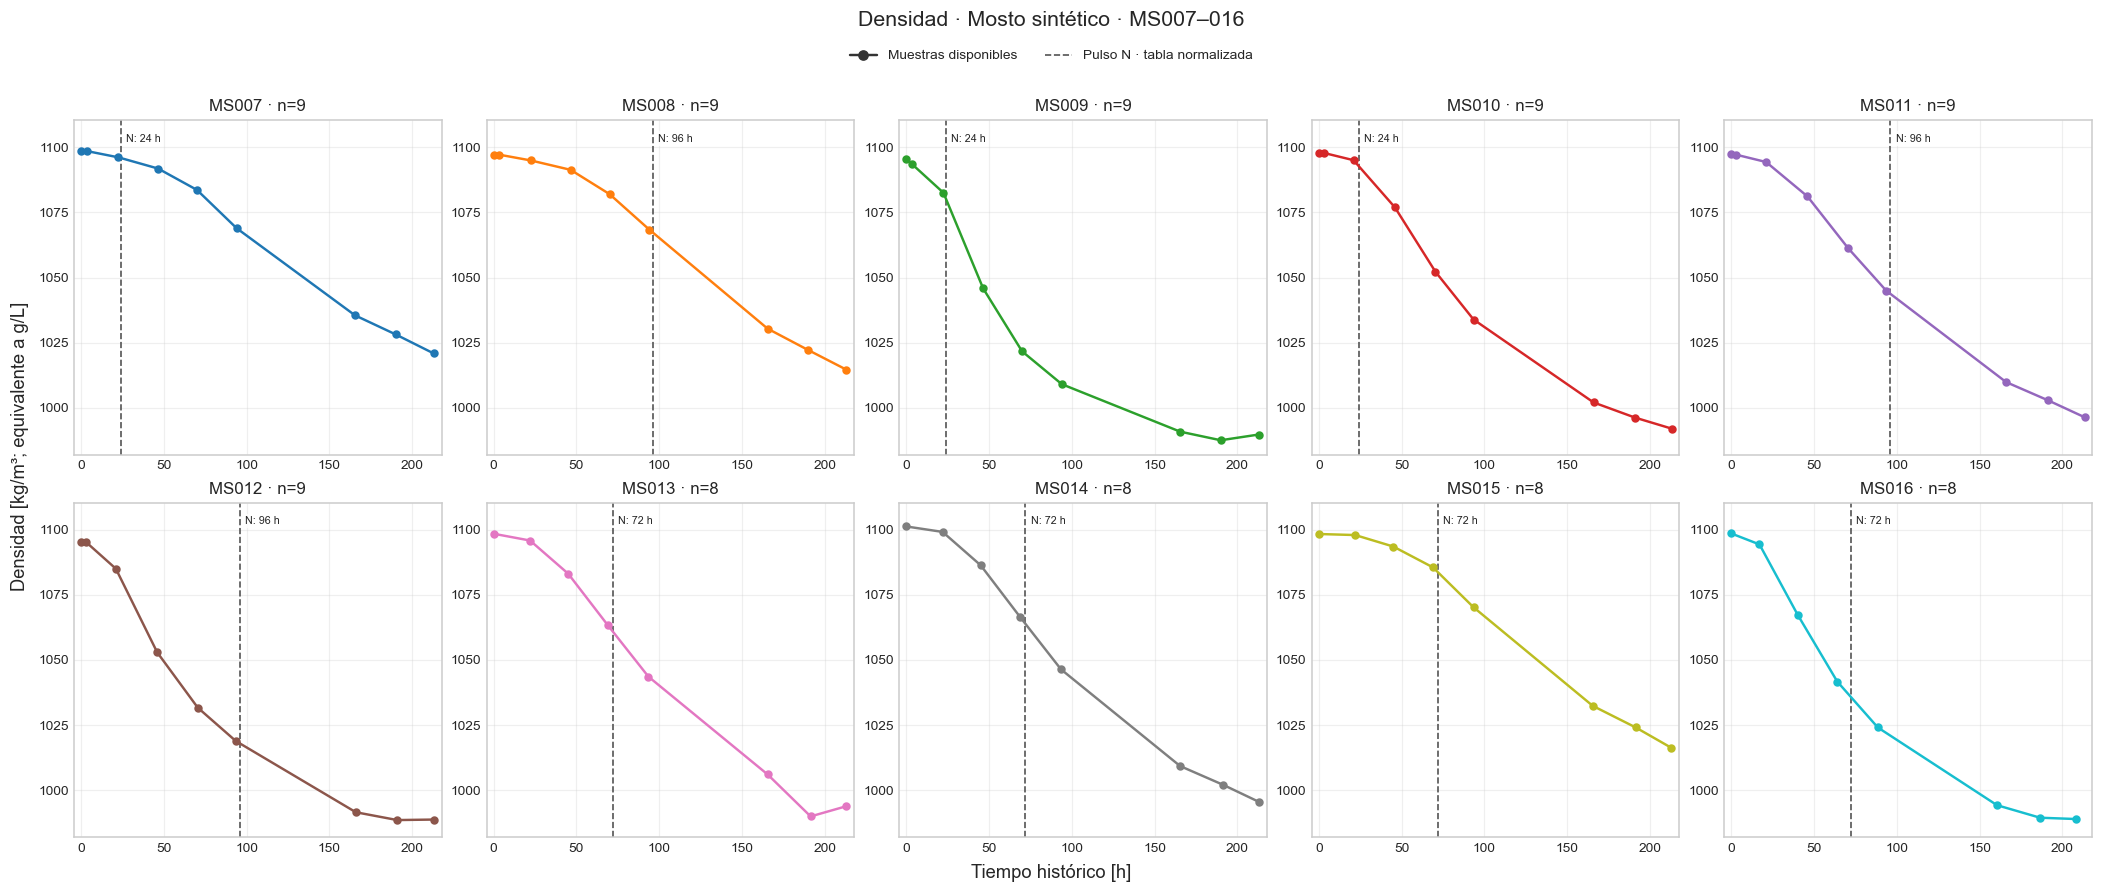

In [14]:
plot_matrix('density', 'Densidad', 'Densidad [kg/m³; equivalente a g/L]', 'synthetic')

## 7. Etanol

Se usa E_g_l, la concentración de etanol normalizada que consume el modelo. Los sintéticos tienen cuatro puntos por experimento; las líneas solo unen esas mediciones.

Primero mosto natural; después mosto sintético.

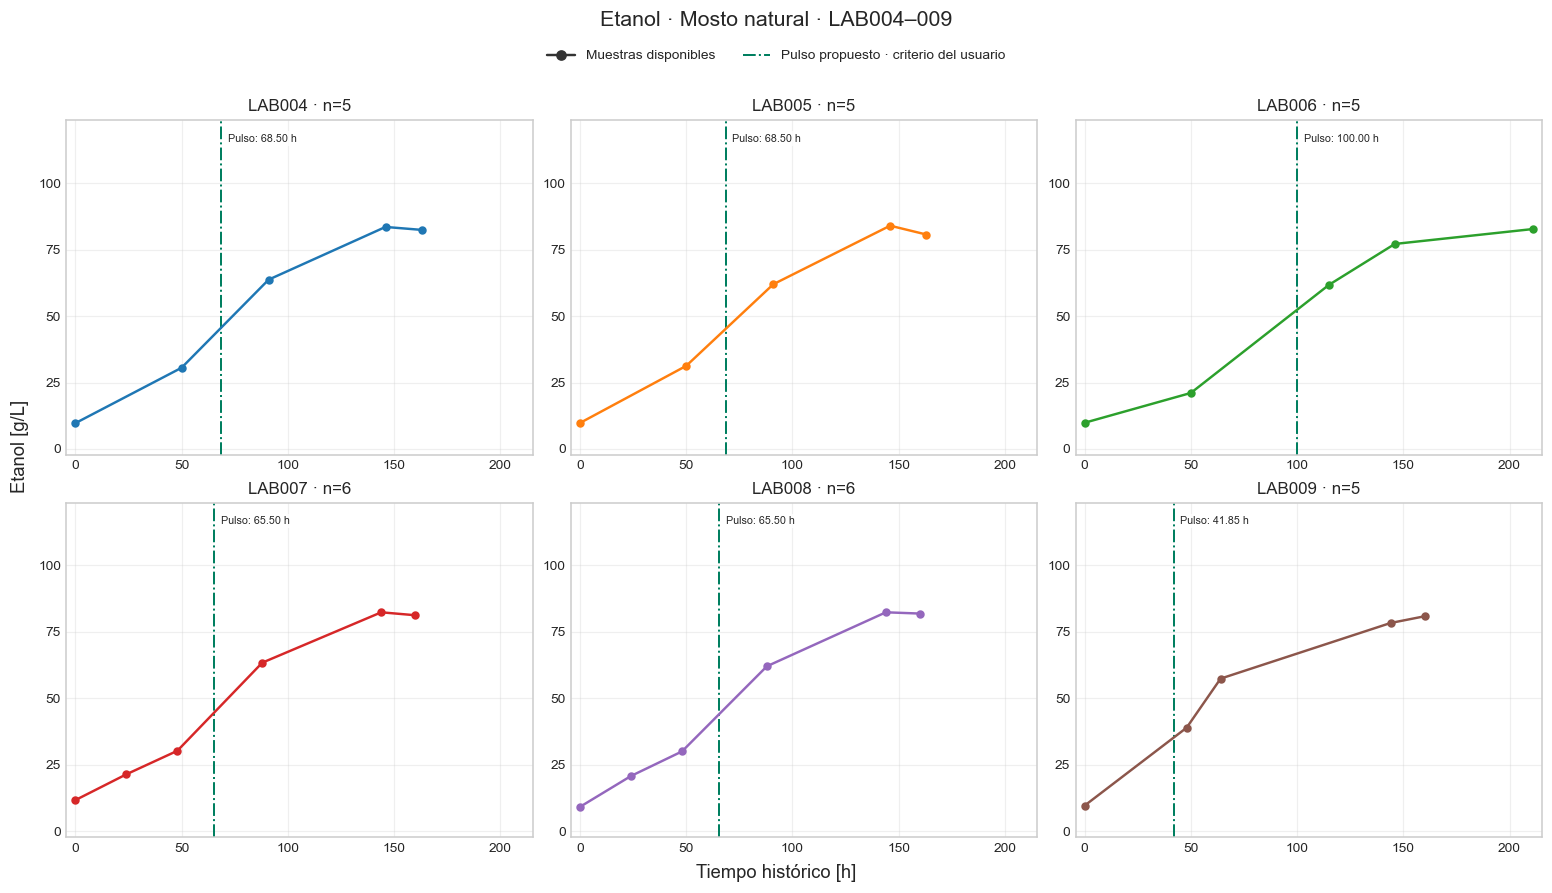

In [15]:
plot_matrix('E_g_l', 'Etanol', 'Etanol [g/L]', 'natural')

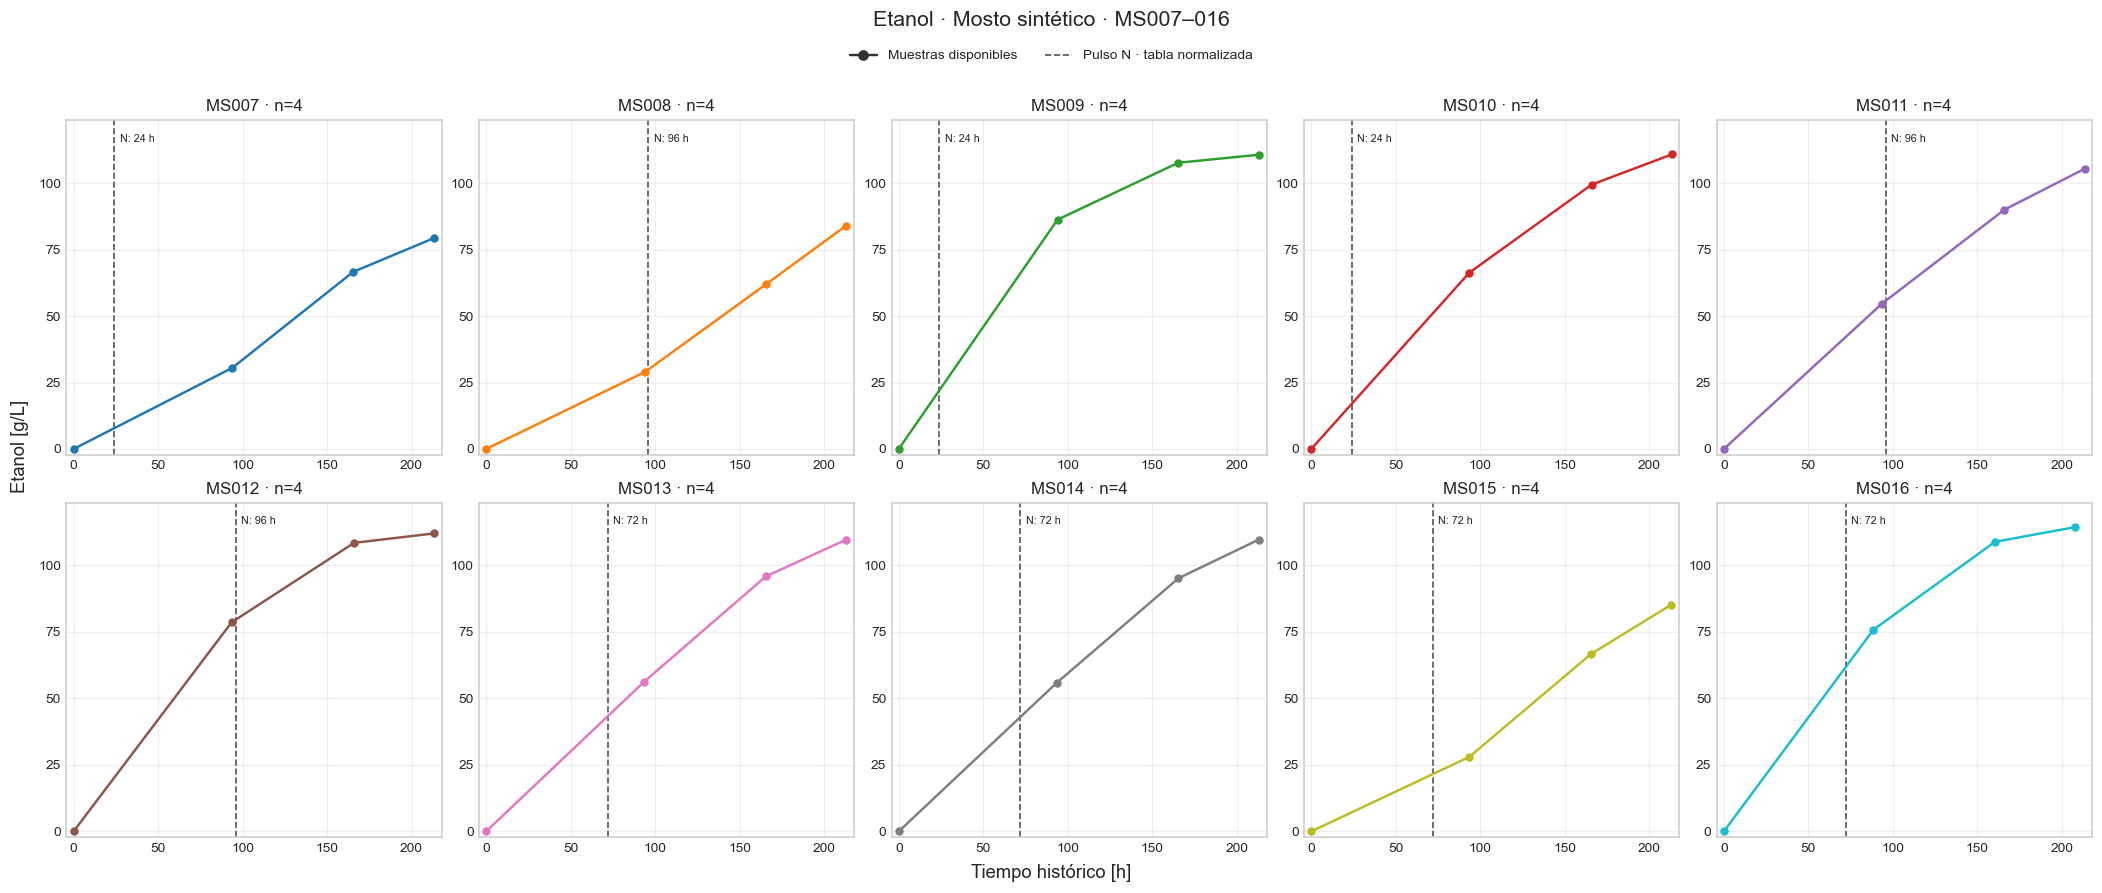

In [16]:
plot_matrix('E_g_l', 'Etanol', 'Etanol [g/L]', 'synthetic')

## 8. Temperatura y activaciones de bomba

Se conserva la selección **LAB004–009** y **MS007–016**; LAB010–012 no se incluyen.

**Referencia del filtro.** `chemistry_lab004_012_theta_comparison` muestra el sensor archivado con medianas de 30 minutos y su representación en la malla del modelo; no aplica Butterworth ni un filtro adicional. Aquí se reconstruyen los logs crudos naturales, se calculan las mismas medianas de 30 minutos y se suavizan más: mediana móvil centrada de tres intervalos (90 minutos), seguida de Butterworth de orden 2, período de corte de 4 h, aplicado hacia delante y atrás (sin desfase). Es una preparación visual, no una nueva temperatura de calibración.

Se filtra por tramos: no se atraviesan intervalos de 30 min sin datos ni cambios registrados de setpoint mayores de 0.5 °C. Los tramos demasiado cortos conservan la mediana móvil y se identifican en la auditoría. No se excluyen ventanas alrededor de la nutrición. Los vacíos de registro permanecen visibles.

Se incluye cada log desde el tiempo histórico cero hasta su última lectura disponible, aunque supere la última muestra química.

Las marcas rosadas al pie representan **todos los episodios registrados de `nutricion_activa = 1`** en el intervalo mostrado, sin imponer una duración mínima. Las muestras consecutivas activas forman un episodio; se corta también ante una separación de más de 30 s. Los extremos representan primera y última lectura activa, no tiempos exactos de accionamiento. No se confunden estos registros con dosis de N: la señal representa la orden de bomba de la GUI, sin identificar líquido ni cantidad. La línea verde mantiene el pulso provisional acordado, para comparación.

**Sintéticos:** no se encontraron logs continuos de temperatura/bomba de MS007–016 en los datos del repositorio. Se muestra aparte la columna `Temperatura Medida` del Excel, con la temperatura operacional como referencia. Son muestras espaciadas, no logs: no se aplica el filtro temporal diseñado para señales densas ni se inventan activaciones. El pulso de su tabla se conserva como supuesto archivado, no como evento confirmado por una bomba.


In [17]:
from scipy.signal import butter, sosfiltfilt

LOG_ROOT = ROOT / 'data/original/natural/process_logs'
SYNTHETIC_BOOK = ROOT / 'data/original/synthetic/mosto_sintetico_vl3.xlsx'
TEMP_FILTER = {'median_bin_min':30, 'rolling_bins':3, 'cutoff_period_h':4., 'order':2,
               'max_gap_h':.500001, 'pump_gap_s':30.}
temperature_input_hashes = {SYNTHETIC_BOOK:hashlib.sha256(SYNTHETIC_BOOK.read_bytes()).hexdigest()}
natural_temperature = {}
pump_episodes = {}
temperature_audit_rows = []
log_inventory_rows = []
filter_segments = []
for lab in LABS:
    paths = sorted(p for p in LOG_ROOT.rglob('*.csv')
                   if p.name.lower().startswith('temp')
                   and re.search(rf'lab0*{int(lab[3:])}(?:\D|$)', p.name, re.IGNORECASE))
    assert paths, f'Sin logs: {lab}'
    fragments = []
    for path in paths:
        temperature_input_hashes[path] = hashlib.sha256(path.read_bytes()).hexdigest()
        part = pd.read_csv(path, usecols=lambda c:c in ('timestamp','T','SP','nutricion_activa','freq_nut'))
        assert {'timestamp','T','SP','nutricion_activa'}.issubset(part.columns)
        part['timestamp'] = pd.to_datetime(part.timestamp, errors='coerce')
        for col in ['T','SP','nutricion_activa','freq_nut']:
            part[col] = pd.to_numeric(part[col], errors='coerce')
        part = part.dropna(subset=['timestamp'])
        log_inventory_rows.append({'LAB':lab,'archivo':str(path.relative_to(ROOT)),
            'n_registros':len(part),'inicio':part.timestamp.min(),'fin':part.timestamp.max()})
        fragments.append(part)
    records = pd.concat(fragments,ignore_index=True).sort_values('timestamp',kind='stable')
    # Las copias coincidentes deben coincidir en señal y estado, sin escoger una arbitrariamente.
    duplicated = records[records.timestamp.duplicated(keep=False)]
    if len(duplicated):
        assert duplicated.groupby('timestamp')[['T','SP','nutricion_activa']].nunique().le(1).all().all()
    records = records.drop_duplicates('timestamp').reset_index(drop=True)
    t0 = pd.Timestamp(clocks.loc[lab,'t0'])
    horizon = float(selected.loc[selected.batch.eq(lab),'time_h'].max())
    records['t_h'] = (records.timestamp-t0).dt.total_seconds()/3600.
    records = records[records.t_h.ge(0)].copy()
    horizon = float(records.t_h.max())
    assert len(records)
    # Episodios desde el log denso, antes de cualquier resumen de temperatura.
    starts=[]; ends=[]; samples=[]; current=[]; previous=None
    for row in records.itertuples(index=False):
        active = pd.notna(row.nutricion_activa) and row.nutricion_activa==1
        if current and (not active or (row.timestamp-previous).total_seconds()>TEMP_FILTER['pump_gap_s']):
            starts.append(current[0]); ends.append(current[-1]); samples.append(len(current)); current=[]
        if active:
            current.append(row.timestamp)
        previous=row.timestamp
    if current:
        starts.append(current[0]); ends.append(current[-1]); samples.append(len(current))
    events = pd.DataFrame({'inicio':starts,'fin':ends,'n_lecturas':samples})
    events['inicio_h'] = (pd.to_datetime(events.inicio)-t0).dt.total_seconds()/3600.
    events['fin_h'] = (pd.to_datetime(events.fin)-t0).dt.total_seconds()/3600.
    events['LAB']=lab
    pump_episodes[lab]=events
    assert sum(samples)==int(records.nutricion_activa.eq(1).sum())
    valid = records.dropna(subset=['T']).set_index('timestamp')
    sensor = valid[['T','SP']].resample('30min').median().dropna(subset=['T']).reset_index()
    sensor['t_h']=(sensor.timestamp-t0).dt.total_seconds()/3600.
    # La mediana se fecha en el centro de cada intervalo de 30 min (resumen offline).
    sensor['t_h'] += .25
    sensor = sensor[sensor.t_h.between(0,horizon)].copy()
    split = sensor.t_h.diff().gt(TEMP_FILTER['max_gap_h']) | sensor.SP.diff().abs().gt(.5)
    sensor['segment']=split.cumsum()
    sensor['filtrada']=np.nan
    sos=butter(TEMP_FILTER['order'],1/TEMP_FILTER['cutoff_period_h'],fs=2.,output='sos')
    for segment, group in sensor.groupby('segment'):
        values=group['T']
        smooth=values.rolling(TEMP_FILTER['rolling_bins'],center=True,min_periods=1).median().to_numpy()
        filtered=sosfiltfilt(sos,smooth) if len(smooth)>9 else smooth.copy()
        sensor.loc[group.index,'filtrada']=filtered
        filter_segments.append({'LAB':lab,'tramo':int(segment),'n_intervalos':len(group),
            'inicio_h':group.t_h.min(),'fin_h':group.t_h.max(),'butterworth_aplicado':len(smooth)>9})
    assert np.isfinite(sensor.filtrada).all()
    natural_temperature[lab]=sensor
    temperature_audit_rows.append({'LAB':lab,'n_archivos':len(paths),'n_lecturas_T':int(records['T'].notna().sum()),
        'inicio_log_h':records.t_h.min(),'fin_log_h':records.t_h.max(),'n_activaciones':len(events),
        'n_lecturas_bomba_activa':sum(samples),'pulso_propuesto_h':proposed_times[lab]})
log_inventory=pd.DataFrame(log_inventory_rows)
temperature_audit=pd.DataFrame(temperature_audit_rows)
filter_segment_audit=pd.DataFrame(filter_segments)
display(temperature_audit.round(3))
display(log_inventory)
display(filter_segment_audit.groupby('LAB').agg(tramos=('tramo','size'),
    tramos_con_butterworth=('butterworth_aplicado','sum')))
# Tabla detallada inline; no exporta CSV ni altera las tablas químicas.
all_pump_episodes=pd.concat(pump_episodes.values(),ignore_index=True)
with pd.option_context('display.max_rows',20):
    display(all_pump_episodes)

,LAB,n_archivos,n_lecturas_T,inicio_log_h,fin_log_h,n_activaciones,n_lecturas_bomba_activa,pulso_propuesto_h
0,LAB004,2,196727,1.770,190.661,116,845,68.500
1,LAB005,2,196715,1.782,190.674,62,576,68.500
2,LAB006,2,220395,1.790,213.665,2,3,100.000
3,LAB007,1,143525,0.001,161.625,149,710,65.500
4,LAB008,1,143527,0.000,161.626,69,458,65.500
5,LAB009,1,143528,0.000,161.628,1,1,41.846


,LAB,archivo,n_registros,inicio,fin
0,LAB004,data\original\natural\process_logs\Desktop_CyT...,17346,2026-04-06 14:46:13,2026-04-07 07:13:27
1,LAB004,data\original\natural\process_logs\Temp_F1_lab...,179381,2026-04-07 08:20:22,2026-04-14 11:39:40
2,LAB005,data\original\natural\process_logs\Desktop_CyT...,17333,2026-04-06 14:46:55,2026-04-07 07:13:24
3,LAB005,data\original\natural\process_logs\Temp_F2_LAB...,179382,2026-04-07 08:21:03,2026-04-14 11:40:25
4,LAB006,data\original\natural\process_logs\Desktop_CyT...,17325,2026-04-06 14:47:23,2026-04-07 07:13:25
5,LAB006,data\original\natural\process_logs\Temp_F3_LAB...,203070,2026-04-07 08:21:28,2026-04-15 10:39:55
6,LAB007,data\original\natural\process_logs\Temp_F1_lab...,148435,2026-04-17 11:20:36,2026-04-24 09:37:30
7,LAB008,data\original\natural\process_logs\Temp_F2_lab...,148426,2026-04-17 11:21:11,2026-04-24 09:37:35
8,LAB009,data\original\natural\process_logs\Temp_F3_lab...,148421,2026-04-17 11:21:32,2026-04-24 09:37:39


,tramos,tramos_con_butterworth
LAB,,
LAB004,4,4
LAB005,4,4
LAB006,3,3
LAB007,2,2
LAB008,2,2
LAB009,2,2


,inicio,fin,n_lecturas,inicio_h,fin_h,LAB
0,2026-04-06 14:46:13,2026-04-06 14:46:23,4,1.770278,1.773056,LAB004
1,2026-04-06 14:51:13,2026-04-06 14:51:24,4,1.853611,1.856667,LAB004
2,2026-04-06 14:51:37,2026-04-06 14:51:58,7,1.860278,1.866111,LAB004
3,2026-04-07 08:55:14,2026-04-07 08:55:28,5,19.920556,19.924444,LAB004
4,2026-04-07 08:55:41,2026-04-07 08:55:51,4,19.928056,19.930833,LAB004
...,...,...,...,...,...,...
394,2026-04-24 09:02:23,2026-04-24 09:02:42,6,161.039722,161.045000,LAB008
395,2026-04-24 09:02:50,2026-04-24 09:02:54,2,161.047222,161.048333,LAB008
396,2026-04-24 09:19:52,2026-04-24 09:20:07,5,161.331111,161.335278,LAB008
397,2026-04-24 09:34:35,2026-04-24 09:34:39,2,161.576389,161.577500,LAB008


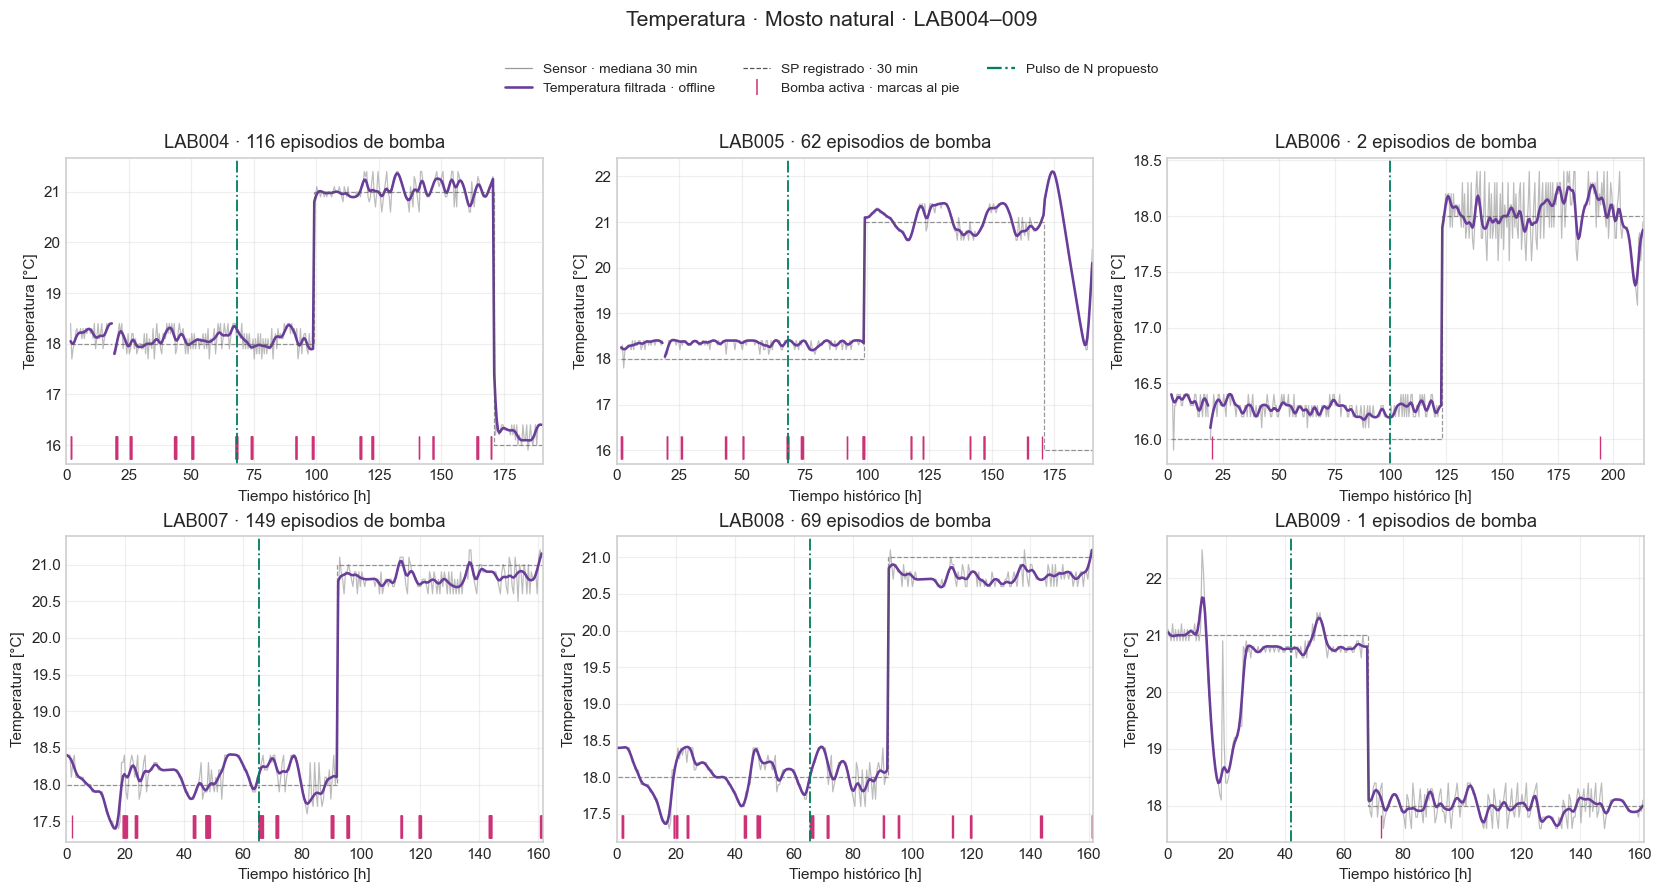

In [18]:
fig,axes=plt.subplots(2,3,figsize=(15,8),layout='constrained')
for ax,lab in zip(axes.flat,LABS):
    sensor=natural_temperature[lab]
    # Unir el salto térmico visible sin suavizarlo; romper solo los huecos reales.
    display_segments=sensor.t_h.diff().gt(TEMP_FILTER['max_gap_h']).cumsum()
    for segment,group in sensor.groupby(display_segments):
        ax.plot(group.t_h,group['T'],color='#999999',lw=.8,alpha=.65)
        ax.plot(group.t_h,group.filtrada,color='#6A3D9A',lw=1.7)
        ax.step(group.t_h,group.SP,where='mid',color='#555555',ls='--',lw=.8,alpha=.6)
    events=pump_episodes[lab]
    for event in events.itertuples():
        ax.plot([event.inicio_h,event.fin_h],[.045,.045],color='#CC3377',lw=3,
                solid_capstyle='butt',transform=ax.get_xaxis_transform())
        ax.vlines(event.inicio_h,.015,.09,color='#CC3377',lw=.9,transform=ax.get_xaxis_transform())
    ax.axvline(proposed_times[lab],color='#007F5F',ls='-.',lw=1.2)
    horizon=float(temperature_audit.set_index('LAB').loc[lab,'fin_log_h'])
    ax.set(title=f'{lab} · {len(events)} episodios de bomba',xlim=(0,horizon),
           xlabel='Tiempo histórico [h]',ylabel='Temperatura [°C]')
    ax.grid(alpha=.3)
handles=[Line2D([],[],color='#999999',lw=.8,label='Sensor · mediana 30 min'),
         Line2D([],[],color='#6A3D9A',lw=1.7,label='Temperatura filtrada · offline'),
         Line2D([],[],color='#555555',ls='--',lw=.8,label='SP registrado · 30 min'),
         Line2D([],[],color='#CC3377',marker='|',ls='none',markersize=10,label='Bomba activa · marcas al pie'),
         Line2D([],[],color='#007F5F',ls='-.',label='Pulso de N propuesto')]
fig.suptitle('Temperatura · Mosto natural · LAB004–009',y=.995,fontsize=14)
fig.get_layout_engine().set(rect=(0,0,1,.86))
fig.legend(handles=handles,loc='upper center',bbox_to_anchor=(.5,.95),ncol=3,frameon=False,fontsize=9)
plt.show(); plt.close(fig)

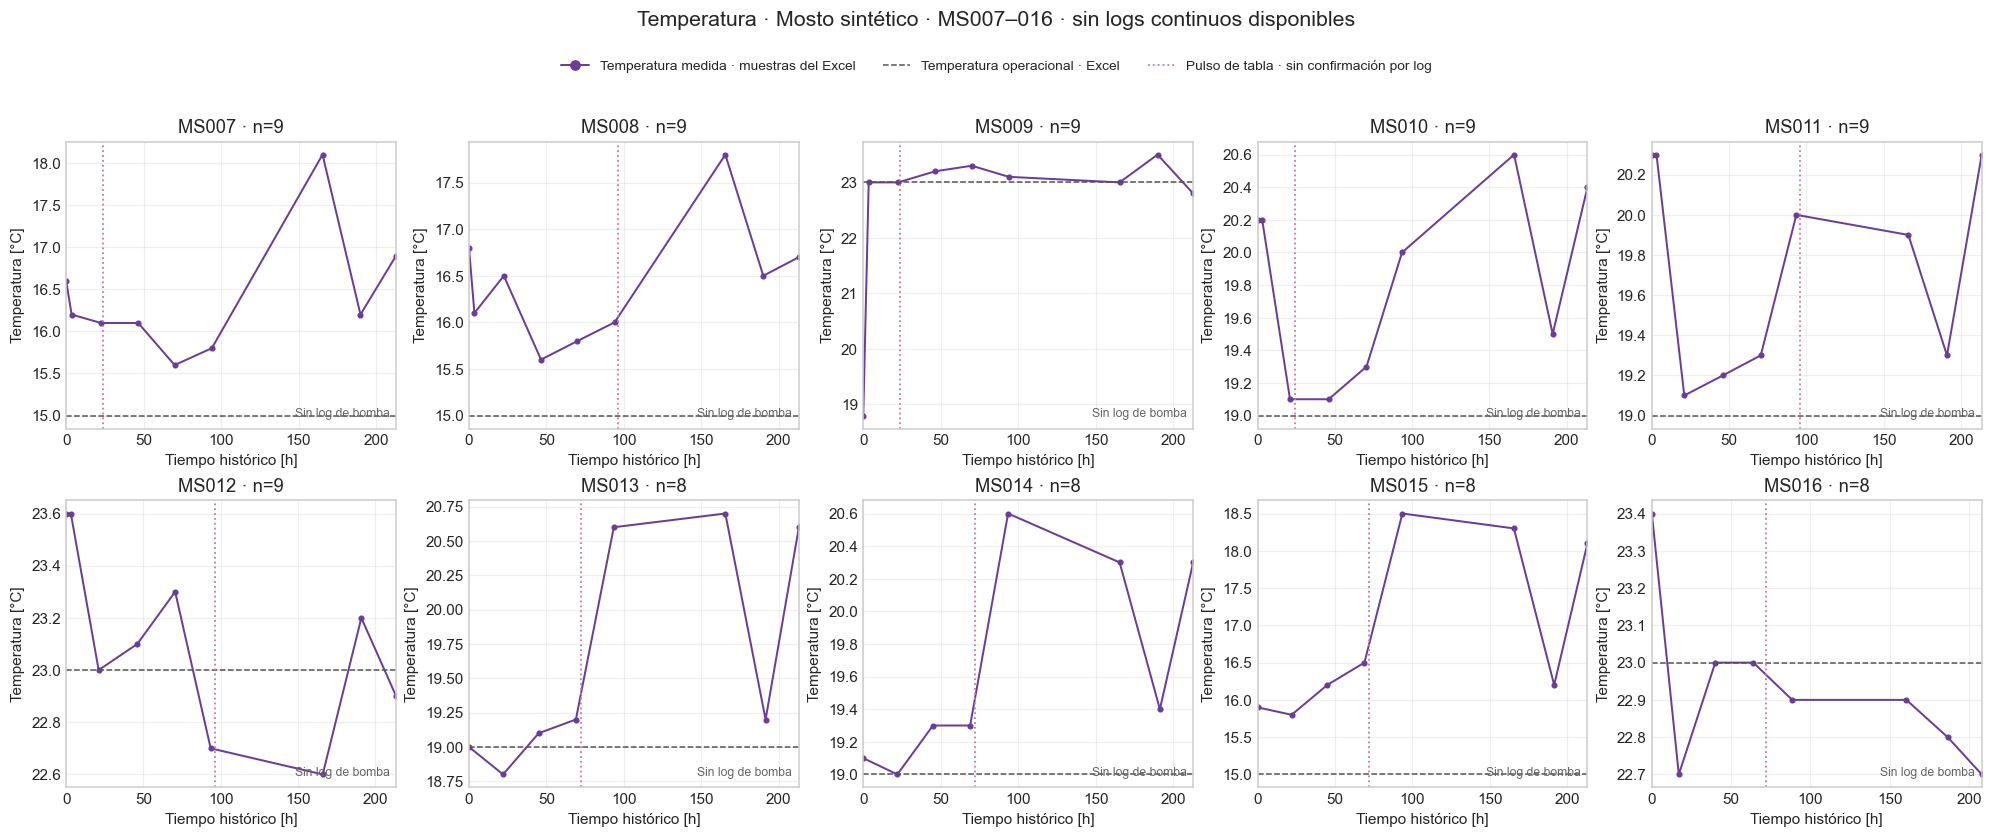

,MS,muestras_T_medida,log_continuo_disponible,activaciones_bomba_disponibles
0,MS007,9,False,False
1,MS008,9,False,False
2,MS009,9,False,False
3,MS010,9,False,False
4,MS011,9,False,False
5,MS012,9,False,False
6,MS013,8,False,False
7,MS014,8,False,False
8,MS015,8,False,False
9,MS016,8,False,False


Verificado: 2 matrices de temperatura añadidas, 6 naturales + 10 sintéticos; fuentes intactas.


In [19]:
synthetic_temperature={}
for lab in SYNTHETIC_LABS:
    sheet=pd.read_excel(SYNTHETIC_BOOK,sheet_name=lab,usecols=['t','Temperatura Medida','temperatura'])
    for col in sheet.columns:
        sheet[col]=pd.to_numeric(sheet[col],errors='coerce')
    sheet=sheet.dropna(subset=['t']).sort_values('t')
    assert sheet['Temperatura Medida'].notna().sum()>=2
    synthetic_temperature[lab]=sheet
fig,axes=plt.subplots(2,5,figsize=(18,7.5),layout='constrained')
for ax,lab in zip(axes.flat,SYNTHETIC_LABS):
    sheet=synthetic_temperature[lab]
    measured=sheet.dropna(subset=['Temperatura Medida'])
    nominal=sheet.dropna(subset=['temperatura'])
    ax.plot(measured.t,measured['Temperatura Medida'],color='#6A3D9A',marker='o',ms=3,lw=1.3)
    ax.plot(nominal.t,nominal.temperatura,color='#555555',ls='--',lw=1)
    for pulse in synthetic_nutrition[synthetic_nutrition.batch.eq(lab)].itertuples():
        ax.axvline(pulse.time_h,color='#CC79A7',ls=':',lw=1.2)
    ax.set(title=f'{lab} · n={len(measured)}',xlabel='Tiempo histórico [h]',ylabel='Temperatura [°C]',
           xlim=(0,float(sheet.t.max())))
    ax.text(.98,.04,'Sin log de bomba',transform=ax.transAxes,ha='right',fontsize=8,color='#666666')
    ax.grid(alpha=.3)
handles=[Line2D([],[],color='#6A3D9A',marker='o',lw=1.3,label='Temperatura medida · muestras del Excel'),
         Line2D([],[],color='#555555',ls='--',lw=1,label='Temperatura operacional · Excel'),
         Line2D([],[],color='#CC79A7',ls=':',lw=1.2,label='Pulso de tabla · sin confirmación por log')]
fig.suptitle('Temperatura · Mosto sintético · MS007–016 · sin logs continuos disponibles',y=.995,fontsize=14)
fig.get_layout_engine().set(rect=(0,0,1,.87))
fig.legend(handles=handles,loc='upper center',bbox_to_anchor=(.5,.95),ncol=3,frameon=False,fontsize=9)
plt.show(); plt.close(fig)
display(pd.DataFrame([{'MS':lab,'muestras_T_medida':int(sheet['Temperatura Medida'].notna().sum()),
    'log_continuo_disponible':False,'activaciones_bomba_disponibles':False}
    for lab,sheet in synthetic_temperature.items()]))
assert set(natural_temperature)==set(LABS) and set(synthetic_temperature)==set(SYNTHETIC_LABS)
assert not any(lab in natural_temperature for lab in ['LAB010','LAB011','LAB012'])
assert all(hashlib.sha256(p.read_bytes()).hexdigest()==h for p,h in temperature_input_hashes.items())
assert sum(temperature_audit.n_lecturas_bomba_activa)==int(all_pump_episodes.n_lecturas.sum())
print('Verificado: 2 matrices de temperatura añadidas, 6 naturales + 10 sintéticos; fuentes intactas.')

## Verificación y alcance

Esta vista reúne 16 experimentos y siete variables, sin ajustar parámetros ni modificar las fuentes. Los recuentos de cada panel se contrastan con la tabla de cobertura, y se comprueba que las escalas verticales coincidan entre matrices. Los faltantes permanecen ausentes. Las líneas entre muestras no permiten afirmar qué ocurrió dentro de los intervalos sin medición; esto es especialmente relevante para el etanol sintético. Glicerol y biomasa muerta no se muestran por el alcance solicitado, aunque el modelo actual todavía los contiene.

In [20]:
assert len(plot_audit) == 14
expected_order = [(column, medium) for column, _, _ in VARIABLES for medium in MATRICES]
assert [(row['variable'], row['medium']) for row in plot_audit] == expected_order
for i, (column, _, _) in enumerate(VARIABLES):
    natural, synthetic = plot_audit[2*i:2*i+2]
    assert natural['ylim'] == synthetic['ylim']
    for entry in (natural, synthetic):
        medium = entry['medium']
        assert entry['n_panels'] == len(MATRICES[medium])
        expected = selected.loc[selected.medium.eq(medium)].groupby('batch')[column].count().to_dict()
        assert entry['counts'] == expected
assert sum(plot_audit[0]['counts'].values()) == 70
assert all(n == 4 for n in plot_audit[-1]['counts'].values())
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == input_hash
assert all(hashlib.sha256(p.read_bytes()).hexdigest()==h for p,h in nutrition_input_hashes.items())
print('Verificado: 16 experimentos, 7 variables, 14 figuras y 112 paneles; fuentes intactas.')

assert [row['variable'] for row in plot_audit if row['compares_density_1040']] == ['YAN_mg_l']
assert all(row['medium']=='natural' for row in plot_audit if row['compares_density_1040'])
assert len(density_crossings)==6 and abs(density_times['LAB006']-74.)<1e-9

assert [row['medium'] for row in plot_audit if row['uses_proposed_pulse']] == ['natural']*7
assert all(abs(proposed_times[lab]-value)<1e-9 for lab,value in
           {'LAB004':68.5,'LAB005':68.5,'LAB006':100.,'LAB007':65.5,'LAB008':65.5}.items())
assert abs(proposed_times['LAB009']-density_times['LAB009'])<1e-12


Verificado: 16 experimentos, 7 variables, 14 figuras y 112 paneles; fuentes intactas.


## Auditoría de tratamientos antes de calibrar

Se revisaron el notebook temprano fermentation_model_calibration_3_effective_reformulation, shared/new_must_data_loader.py, shared/run_new_must_glycerol_estimability_doe.py, shared/run_secondary_joint_campaign_doe.py, laboratory_2026/run_estimability_historical_by_medium.py y el SOURCE theta_new de recalibration. Se inspeccionó código, no sólo documentación.

| Ruta | Tratamiento efectivo |
|---|---|
| Prototipo temprano Pyomo | YAN <=20mg/L sustituido por0; desde el primer agotamiento después del último pulso se omite YAN posterior a12h y biomasa posterior a24h. Pulso inicial añadido aN0 cuando corresponde. Pulsos medidos suavizados durante3h después de la muestra. Biomasa con error multiplicado por3 y mínimo0.50g/L. Estas reglas NO se aplican automáticamente al notebook adaptado. |
| theta_full histórico, ruta estimability_historical_natural | Loader de tablas normalizadas; negativos químicos proyectados a0; faltantes ausentes. Eventos de N tomados de filas tabuladas con N_pulse positivo. Iniciales primer valor finito; temperatura natural de logs sobre malla enriquecida y nominal fuera de cobertura. make_secondary_batches parte de make_batches sin la regla20mg/L ni los cortes12/24h. Simulación con saltos de dosis, no el suavizado3h del prototipo. |
| Recalibración theta_new en recalibration | LAB004–009 depurados; seis exclusiones Oculyze y tres correcciones manuales. Cambia horarios leyendo pulso real del Excel, sin mover observaciones ni duplicar dosis. Horarios aceptados/provisionales, no ejecución confirmada pese al nombre de columna. Temperatura de logs: mediana30min, mediana centrada3bins y Butterworth orden2, período4h; segmentado en huecos y saltosSP. Conserva YAN tardío positivo: no aplica automáticamente regla20mg/L. |
| wine-fermentation actual | natural_batches usa CSV depurado, proyecta negativos de estados a0, lee pulso real del Excel depurado, dosis80mg/L y logs filtrados. La preparación aquí no sobrescribe nada. |

Las seis exclusiones Oculyze son LAB004-10, LAB005-10 y LAB006-09 a115h, y LAB007-L-13, LAB008-L-13 y LAB009-L-12 a160h. Sólo se excluyeron sus campos de biomasa, no YAN/azúcar/etanol. Las correcciones a43h son X=1.044/1.5576/0.9195g/L en LAB004/005/006.

La tabla siguiente compara la fila original, calendario, propuesta del notebook y horario usado por el Excel depurado actual. No se confunden con cuatro dosis. El modelo temprano no es automáticamente la procedencia de theta_full: no se deben trasladar sus reglas sin comprobar la ruta de carga.


In [21]:
audit_rows=[]
original_book=ROOT/'data/original/natural/lab004_012/mosto_natural_original.xlsx'
cleaned_book=ROOT/'data/cleaned/natural/lab004_012/mosto_natural_depurado.xlsx'
audit_hashes={p:hashlib.sha256(p.read_bytes()).hexdigest() for p in (original_book,cleaned_book)}
for lab in LABS:
 original_sheet=pd.read_excel(original_book,sheet_name=lab)
 normalized=normalize_must_sheet(original_sheet,'natural',lab,original_book)
 old_events=normalized.loc[normalized.N_pulse_mg_l.gt(0),['time_h','N_pulse_mg_l']]
 cleaned=pd.read_excel(cleaned_book,sheet_name=lab)
 events=cleaned.loc[cleaned['pulso real'].notna()]
 assert len(events)==1
 audit_rows.append(dict(LAB=lab,fila_original_eventos=list(old_events.itertuples(index=False,name=None)),
  calendario_h=nutrition_times[lab],preparing_propuesto_h=proposed_times[lab],
  actual_pulso_real_h=float(events['pulso real'].iloc[0]),dosis_actual_mg_L=float(events.pulso_nut.iloc[0])))
display(pd.DataFrame(audit_rows))
# Mostrar exactamente qué observaciones afectaría la regla temprana; NO alterar las usadas.
legacy_effect=[]
for lab in LABS:
 q=raw.loc[raw.medium.eq('natural')&raw.batch.eq(lab)].sort_values('time_h')
 pulses=q.loc[q.N_pulse_mg_l.gt(0),'time_h'];last=float(pulses.max()) if len(pulses) else float(q.time_h.min())
 depleted=q.loc[q.time_h.ge(last)&q.YAN_mg_l.le(20),'time_h'];td=float(depleted.min()) if len(depleted) else np.nan
 legacy_effect.append(dict(LAB=lab,primer_agotamiento_post_pulso_h=td,
   muestras_YAN_que_se_harian_cero=int(q.YAN_mg_l.le(20).sum()),
   muestras_YAN_tardias_omitidas=int((q.time_h.gt(td+12)&q.YAN_mg_l.notna()).sum()) if pd.notna(td) else 0,
   muestras_X_tardias_omitidas=int((q.time_h.gt(td+24)&q.X_viable_kg_m3.notna()).sum()) if pd.notna(td) else 0))
display(pd.DataFrame(legacy_effect))
print('YAN tardío conservado en la preparación actual:')
display(raw.loc[raw.medium.eq('natural')&raw.batch.isin(LABS)&raw.time_h.ge(88),
 ['batch','sample_id','time_h','YAN_mg_l','PAN_mg_l','NH4_mg_l']])
assert hashlib.sha256(SYNTHETIC_BOOK.read_bytes()).hexdigest()==synthetic_hash
assert all(hashlib.sha256(p.read_bytes()).hexdigest()==h for p,h in audit_hashes.items())


,LAB,fila_original_eventos,calendario_h,preparing_propuesto_h,actual_pulso_real_h,dosis_actual_mg_L
0,LAB004,"[(68.0, 80.0)]",51.50,68.500000,68.500000,80.0
1,LAB005,"[(68.0, 80.0)]",51.50,68.500000,68.500000,80.0
2,LAB006,"[(99.0, 80.0)]",75.50,100.000000,100.000000,80.0
3,LAB007,"[(65.0, 80.0)]",44.75,65.500000,65.500000,80.0
4,LAB008,"[(65.0, 80.0)]",44.75,65.500000,65.500000,80.0
5,LAB009,"[(41.0, 80.0)]",44.75,41.846154,41.846154,80.0


,LAB,primer_agotamiento_post_pulso_h,muestras_YAN_que_se_harian_cero,muestras_YAN_tardias_omitidas,muestras_X_tardias_omitidas
0,LAB004,91.0,5,4,2
1,LAB005,91.0,5,4,2
2,LAB006,NaN,1,0,0
3,LAB007,88.0,5,4,2
4,LAB008,88.0,6,4,2
5,LAB009,64.0,6,5,3


YAN tardío conservado en la preparación actual:


,batch,sample_id,time_h,YAN_mg_l,PAN_mg_l,NH4_mg_l
8,LAB004,ING26-LAB004-08,91.0,9.00,9.0,0.0
9,LAB004,ING26-LAB004-09,98.0,7.00,7.0,0.0
10,LAB004,ING26-LAB004-10,115.0,43.00,43.0,0.0
11,LAB004,ING26-LAB004-11,122.0,11.00,11.0,0.0
12,LAB004,ING26-LAB004-12,146.0,25.00,25.0,0.0
13,LAB004,ING26-LAB004-13,163.0,28.46,26.0,3.0
22,LAB005,ING26-LAB005-08,91.0,11.00,11.0,0.0
23,LAB005,ING26-LAB005-09,98.0,10.00,10.0,0.0
24,LAB005,ING26-LAB005-10,115.0,46.00,46.0,0.0
25,LAB005,ING26-LAB005-11,122.0,14.00,14.0,0.0


## 9. Química y horarios de LAB013–015

Se revisan los registros Y15 y la hoja `All_samples` de la planilla original de LAB013–015. La cobertura distingue las muestras preinóculo de las de fermentación. Se conservan las fechas de análisis Y15 y las de muestreo de la planilla, enlazadas por el identificador exacto de muestra. La hoja `README` indica que el tiempo desde inoculación está pendiente en esta fuente; los gráficos usan fechas y horas absolutas.

Las muestras de fermentación con química se muestran a su hora de muestreo. El preinóculo se ubica a la hora de análisis Y15 y se identifica con un símbolo diferente. Las líneas entre muestras permiten seguir la serie. Las observaciones se reúnen para revisión antes de seleccionar datos de calibración.

YAN corresponde al nitrógeno asimilable por la levadura. Se grafica directamente la columna `YAN_mg_L` del archivo Y15.

In [25]:

REVIEW_LABS = ('LAB013', 'LAB014', 'LAB015')
review_folder = ROOT / 'data/original/natural/lab013_015'
review_csv = review_folder / 'Y15_LAB013-015.csv'
review_book = review_folder / 'LAB013-LAB015-offline-measurements.xlsx'
review_hashes = {path: hashlib.sha256(path.read_bytes()).hexdigest() for path in (review_csv, review_book)}
review_y15 = pd.read_csv(review_csv, parse_dates=['y15_datetime', 'y15_datetime_end'])
review_offline = pd.read_excel(review_book, sheet_name='All_samples')
review_notes = pd.read_excel(review_book, sheet_name='README')
review_offline['sample_datetime'] = pd.to_datetime(review_offline.fecha_muestreo).dt.normalize() + pd.to_timedelta(review_offline.hora_muestreo.astype(str))
assert review_y15.sample_id.is_unique and review_offline.sample_id.is_unique
assert set(review_y15.lab_id) == set(review_offline.lab_id) == set(REVIEW_LABS)
review_joined = review_y15.merge(review_offline[['sample_id', 'lab_id', 'sample_datetime', 'brix_degBx', 'rho_value', 'temperature_C', 'notes']],
                                on=['lab_id', 'sample_id'], how='outer', validate='one_to_one', indicator=True)
review_joined['delay_min'] = (review_joined.y15_datetime - review_joined.sample_datetime).dt.total_seconds() / 60
review_joined['plot_datetime'] = review_joined.sample_datetime.fillna(review_joined.y15_datetime)
review_joined = review_joined.sort_values(['lab_id', 'plot_datetime']).reset_index(drop=True)
review_variables = (
    ('YAN_mg_L', 'YAN', 'mg N/L'),
    ('glucose_g_L', 'Glucosa', 'g/L'),
    ('fructose_g_L', 'Fructosa', 'g/L'),
    ('glucose_fructose_g_L', 'Glucosa + fructosa', 'g/L'),
    ('ammonia_mg_L', 'Amonio', 'mg/L'),
    ('PAN_mg_L', 'Nitrógeno de aminoácidos primarios', 'mg/L'),
    ('glycerol_g_L', 'Glicerol', 'g/L'),
)
coverage_rows = []
for lab in REVIEW_LABS:
    frame = review_y15.loc[review_y15.lab_id.eq(lab)]
    for column, label, unit in review_variables:
        values = pd.to_numeric(frame[column], errors='coerce')
        coverage_rows.append({'LAB': lab, 'Variable': label, 'Unidad': unit,
            'Total': int(values.notna().sum()),
            'Preinóculo': int((values.notna() & frame.sample_type.eq('pre_inoculum')).sum()),
            'Fermentación': int((values.notna() & frame.sample_type.eq('fermentation_sample')).sum()),
            'Primera hora Y15': frame.loc[values.notna(), 'y15_datetime'].min(),
            'Última hora Y15': frame.loc[values.notna(), 'y15_datetime'].max()})
    coverage_rows.append({'LAB': lab, 'Variable': 'Etanol', 'Unidad': 'g/L', 'Total': 0,
                          'Preinóculo': 0, 'Fermentación': 0, 'Primera hora Y15': pd.NaT, 'Última hora Y15': pd.NaT})
review_coverage = pd.DataFrame(coverage_rows)
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(review_coverage)
    display(review_joined[['sample_id', 'sample_type', 'sample_datetime', 'y15_datetime', 'y15_datetime_end', 'delay_min', '_merge']])
display(review_notes.loc[review_notes.iloc[:, 0].astype(str).eq('time_h')])
assert len(review_y15) == 24 and len(review_offline) == 30
assert review_joined['_merge'].eq('both').sum() == 21


,LAB,Variable,Unidad,Total,Preinóculo,Fermentación,Primera hora Y15,Última hora Y15
0,LAB013,YAN,mg N/L,8,1,7,2026-08-18 11:05:18,2026-08-20 15:37:23
1,LAB013,Glucosa,g/L,8,1,7,2026-08-18 11:05:18,2026-08-20 15:37:23
2,LAB013,Fructosa,g/L,8,1,7,2026-08-18 11:05:18,2026-08-20 15:37:23
3,LAB013,Glucosa + fructosa,g/L,8,1,7,2026-08-18 11:05:18,2026-08-20 15:37:23
4,LAB013,Amonio,mg/L,8,1,7,2026-08-18 11:05:18,2026-08-20 15:37:23
5,LAB013,Nitrógeno de aminoácidos primarios,mg/L,8,1,7,2026-08-18 11:05:18,2026-08-20 15:37:23
6,LAB013,Glicerol,g/L,8,1,7,2026-08-18 11:05:18,2026-08-20 15:37:23
7,LAB013,Etanol,g/L,0,0,0,NaT,NaT
8,LAB014,YAN,mg N/L,8,1,7,2026-08-18 11:06:06,2026-08-20 15:38:11
9,LAB014,Glucosa,g/L,8,1,7,2026-08-18 11:06:06,2026-08-20 15:38:11


,sample_id,sample_type,sample_datetime,y15_datetime,y15_datetime_end,delay_min,_merge
0,LAB013-1,NaN,2026-08-18 10:00:00,NaT,NaT,NaN,right_only
1,LAB013-PI,pre_inoculum,NaT,2026-08-18 11:05:18,2026-08-18 11:16:31,NaN,left_only
2,LAB013-2,fermentation_sample,2026-08-18 12:30:00,2026-08-18 13:12:58,2026-08-18 13:21:23,42.966667,both
3,LAB013-3,fermentation_sample,2026-08-18 14:30:00,2026-08-18 15:02:13,2026-08-18 15:09:26,32.216667,both
4,LAB013-4,fermentation_sample,2026-08-18 17:00:00,2026-08-18 17:10:13,2026-08-18 17:24:15,10.216667,both
5,LAB013-5,fermentation_sample,2026-08-19 09:00:00,2026-08-19 11:11:09,2026-08-19 11:34:22,131.150000,both
6,LAB013-6,fermentation_sample,2026-08-19 15:00:00,2026-08-19 15:32:51,2026-08-19 16:06:29,32.850000,both
7,LAB013-7,fermentation_sample,2026-08-20 09:30:00,2026-08-20 10:22:27,2026-08-20 10:38:29,52.450000,both
8,LAB013-8,fermentation_sample,2026-08-20 15:00:00,2026-08-20 15:37:23,2026-08-20 15:45:49,37.383333,both
9,LAB013-9,NaN,2026-08-21 09:30:00,NaT,NaT,NaN,right_only


,Campo / tema,Descripción,Unidad / convención
6,time_h,Horas desde el t=0 de fermentación. Se mantien...,h


### Mediciones químicas y cobertura temporal

Cada fila de paneles muestra una variable con la misma escala vertical para los tres lotes. Los círculos representan muestras de fermentación a la hora de muestreo. Los rombos vacíos representan el preinóculo a la hora de análisis Y15. El etanol queda registrado como ausente en la tabla de cobertura de estas fuentes.

D:\claud\Desktop\wine-fermentation\tmp\preparing_yan_density\run.py:34: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 12.
  f=plt.figure(number);b=io.BytesIO();f.savefig(b,format='png',dpi=110,bbox_inches='tight')


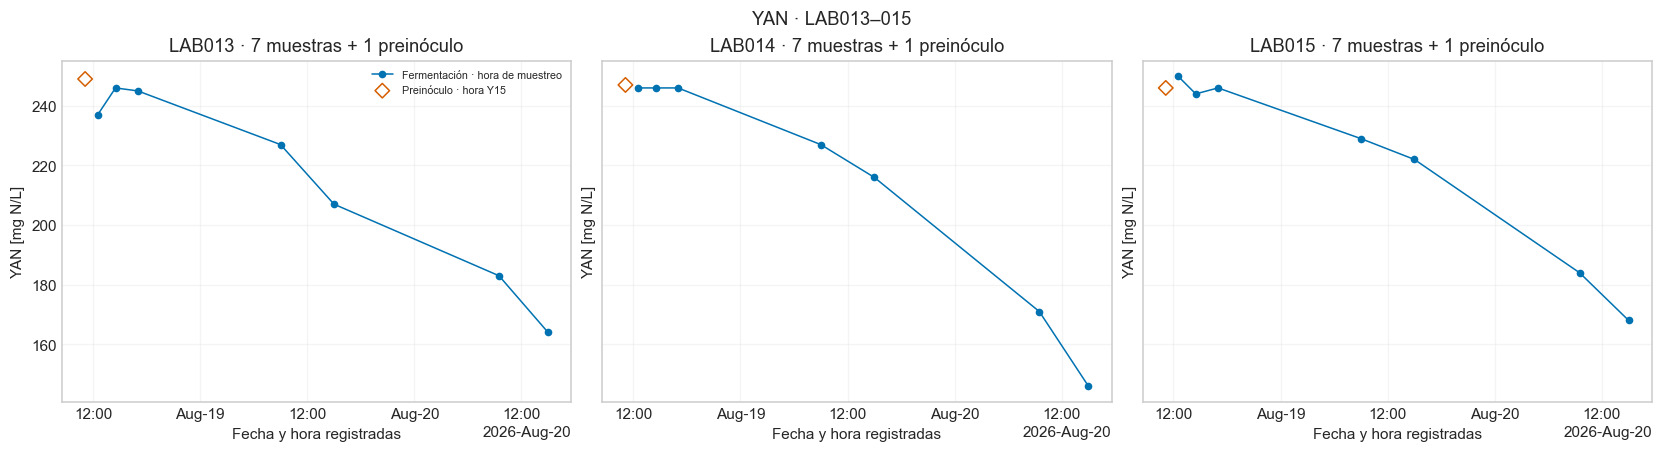

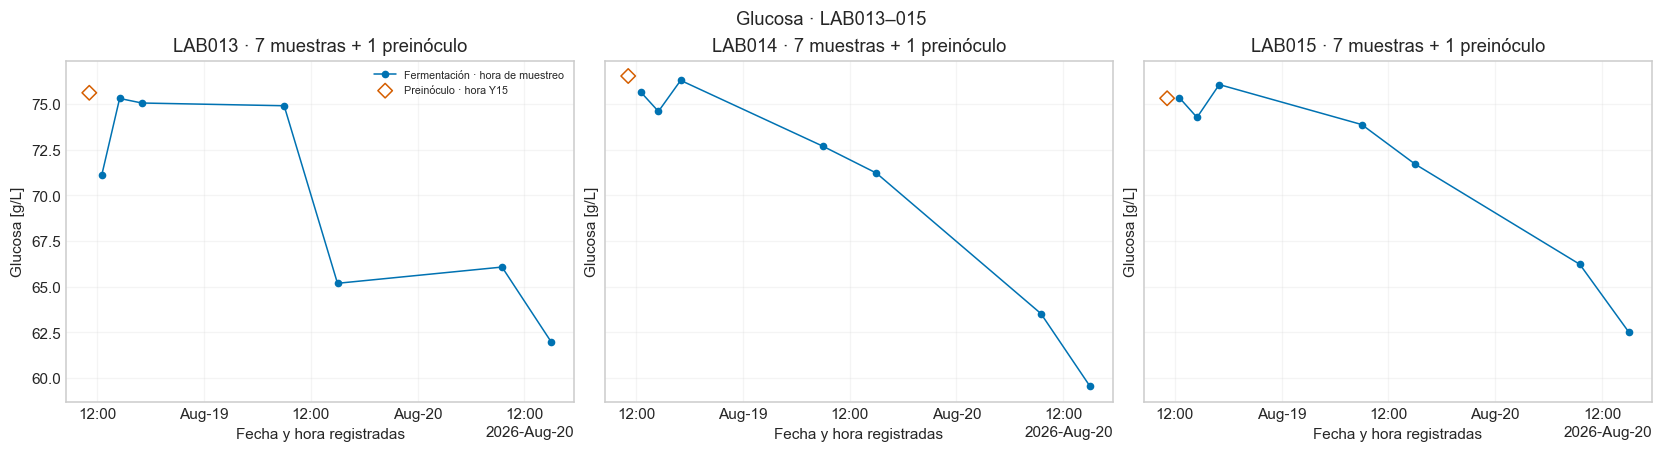

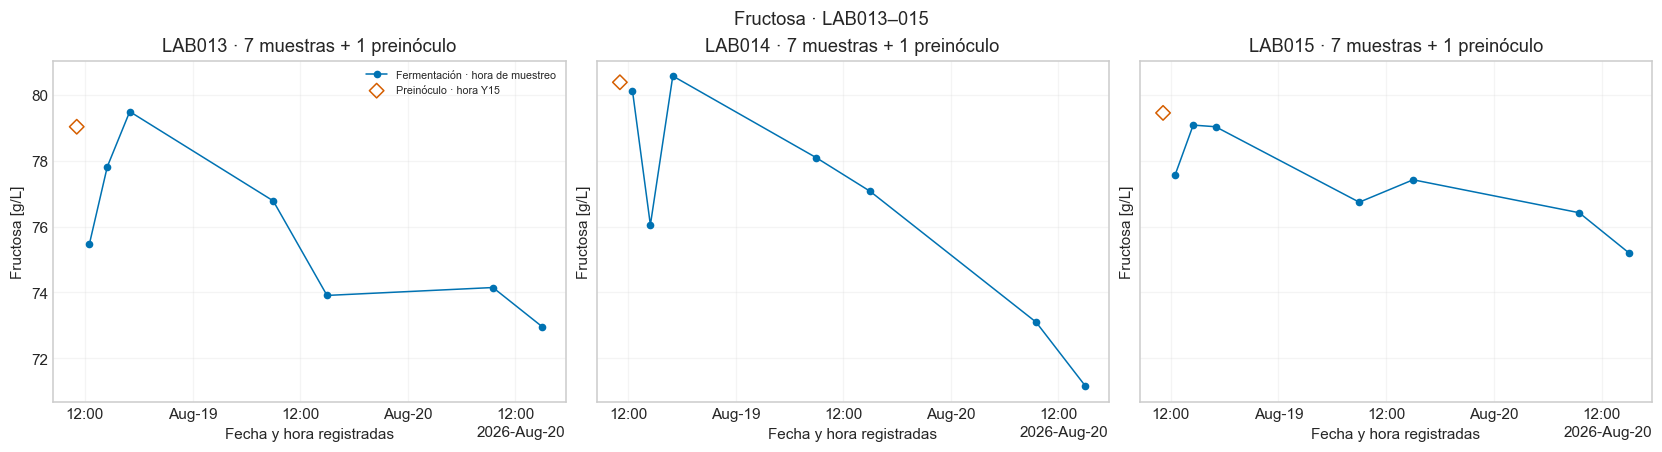

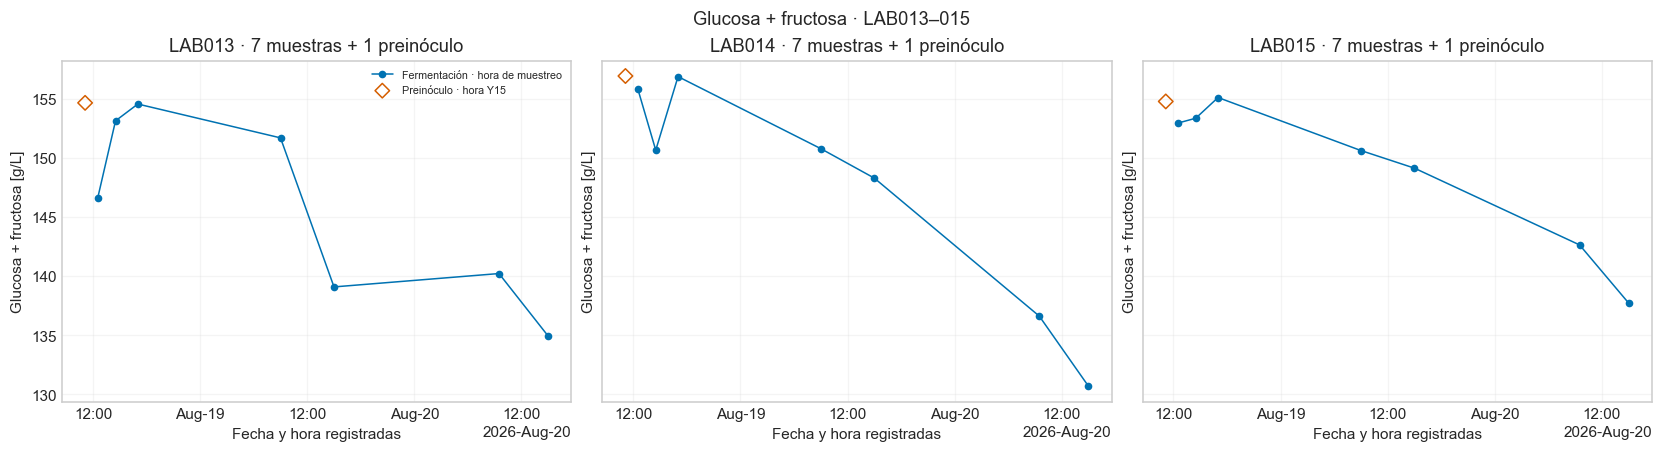

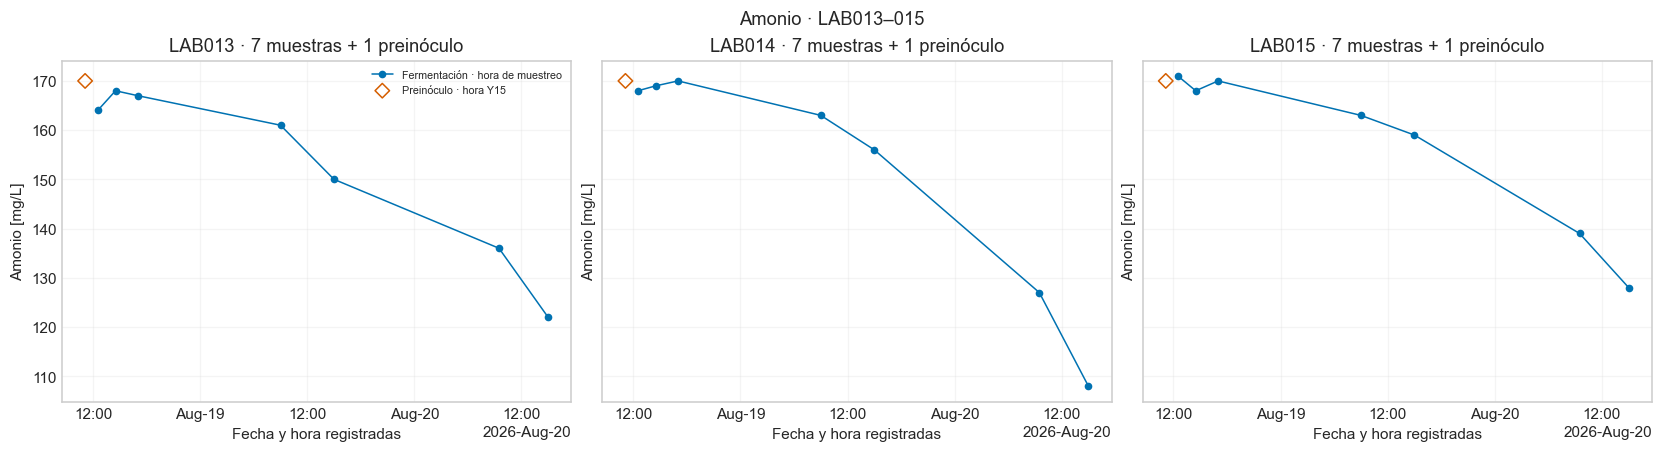

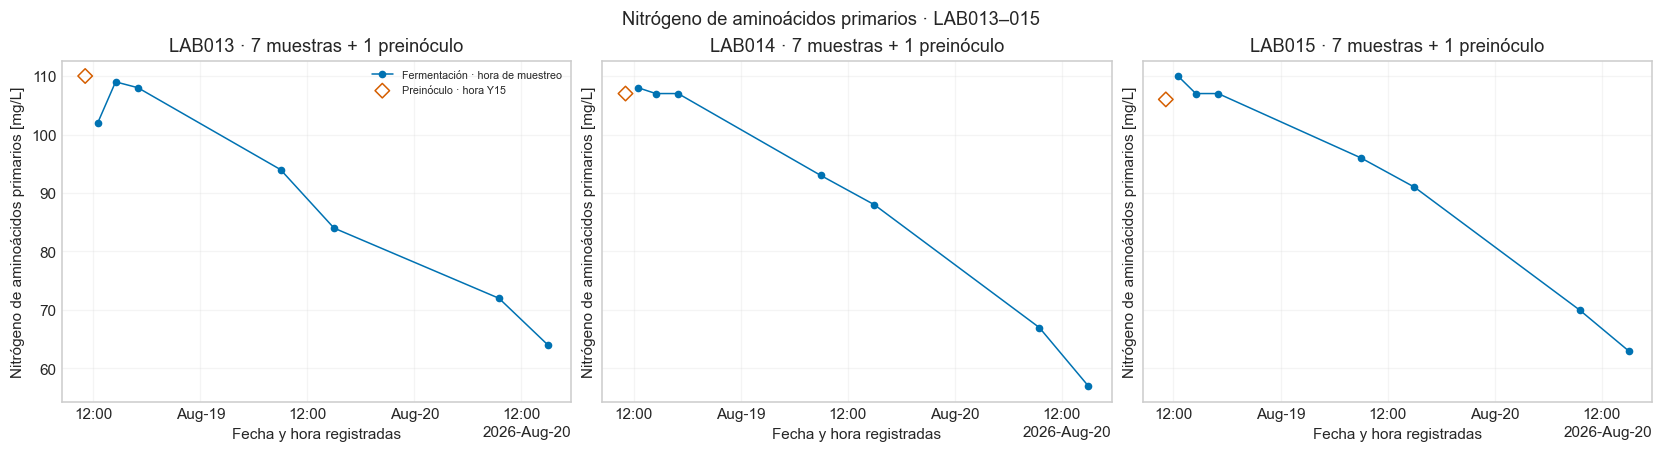

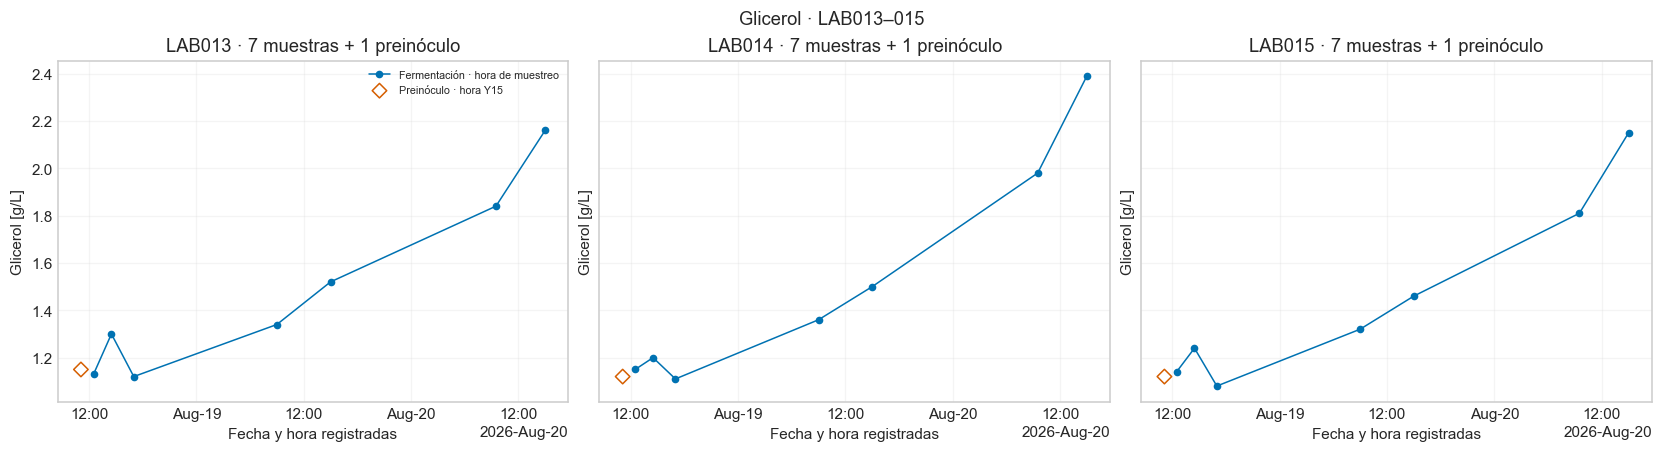

,sample_id,sample_type,sample_datetime,y15_datetime,YAN_mg_L,glucose_g_L,fructose_g_L,glucose_fructose_g_L,ammonia_mg_L,PAN_mg_L,glycerol_g_L
1,LAB013-PI,pre_inoculum,NaT,2026-08-18 11:05:18,249.0,75.62,79.03,154.65,170.0,110.0,1.15
2,LAB013-2,fermentation_sample,2026-08-18 12:30:00,2026-08-18 13:12:58,237.0,71.13,75.47,146.60,164.0,102.0,1.13
3,LAB013-3,fermentation_sample,2026-08-18 14:30:00,2026-08-18 15:02:13,246.0,75.31,77.82,153.13,168.0,109.0,1.30
4,LAB013-4,fermentation_sample,2026-08-18 17:00:00,2026-08-18 17:10:13,245.0,75.06,79.49,154.55,167.0,108.0,1.12
5,LAB013-5,fermentation_sample,2026-08-19 09:00:00,2026-08-19 11:11:09,227.0,74.91,76.78,151.69,161.0,94.0,1.34
6,LAB013-6,fermentation_sample,2026-08-19 15:00:00,2026-08-19 15:32:51,207.0,65.18,73.91,139.09,150.0,84.0,1.52
7,LAB013-7,fermentation_sample,2026-08-20 09:30:00,2026-08-20 10:22:27,183.0,66.07,74.15,140.22,136.0,72.0,1.84
8,LAB013-8,fermentation_sample,2026-08-20 15:00:00,2026-08-20 15:37:23,164.0,61.99,72.96,134.95,122.0,64.0,2.16
12,LAB014-PI,pre_inoculum,NaT,2026-08-18 11:06:06,247.0,76.54,80.38,156.92,170.0,107.0,1.12
13,LAB014-2,fermentation_sample,2026-08-18 12:30:00,2026-08-18 13:13:46,246.0,75.67,80.13,155.80,168.0,108.0,1.15


,Menor diferencia G+F [g/L],Mayor diferencia G+F [g/L]
lab_id,,
LAB013,-1.421085e-14,1.421085e-14
LAB014,-1.421085e-14,1.421085e-14
LAB015,-1.421085e-14,1.421085e-14


In [26]:

import matplotlib.dates as mdates
for column, label, unit in review_variables:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True, layout='constrained')
    for ax, lab in zip(axes, REVIEW_LABS):
        frame = review_joined.loc[review_joined.lab_id.eq(lab)]
        samples = frame.loc[frame.sample_type.eq('fermentation_sample') & frame[column].notna()].sort_values('sample_datetime')
        pre = frame.loc[frame.sample_type.eq('pre_inoculum') & frame[column].notna()]
        ax.plot(samples.sample_datetime, samples[column], 'o-', color='#0072B2', ms=4, lw=1, label='Fermentación · hora de muestreo')
        ax.scatter(pre.y15_datetime, pre[column], marker='D', facecolors='none', edgecolors='#D55E00', s=45,
                   label='Preinóculo · hora Y15', zorder=4)
        locator = mdates.AutoDateLocator(minticks=3, maxticks=5)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
        ax.set(title=f'{lab} · {len(samples)} muestras + {len(pre)} preinóculo', xlabel='Fecha y hora registradas', ylabel=f'{label} [{unit}]')
        ax.grid(alpha=.2)
    axes[0].legend(fontsize=7, loc='best')
    fig.suptitle(f'{label} · LAB013–015')
    plt.show()
with pd.option_context('display.max_columns', None):
    display(review_joined.loc[review_joined.y15_datetime.notna(),
        ['sample_id', 'sample_type', 'sample_datetime', 'y15_datetime', *[column for column, _, _ in review_variables]]])
review_consistency = review_y15.assign(delta_total=lambda x: x.glucose_fructose_g_L - x.glucose_g_L - x.fructose_g_L)
display(review_consistency.groupby('lab_id').delta_total.agg(['min', 'max']).rename(columns={'min':'Menor diferencia G+F [g/L]', 'max':'Mayor diferencia G+F [g/L]'}))


### Horas de muestreo y de análisis

Cada segmento une la hora de extracción de una muestra con la hora de inicio de su análisis Y15. Los registros con una sola hora disponible conservan esa marca. Las diferencias se muestran en minutos y permiten identificar cuándo usar la hora de análisis desplazaría una observación en el tiempo.

Los sólidos solubles y la temperatura de muestra completan la revisión de cobertura de la planilla. Se muestran como mediciones auxiliares con sus unidades originales.

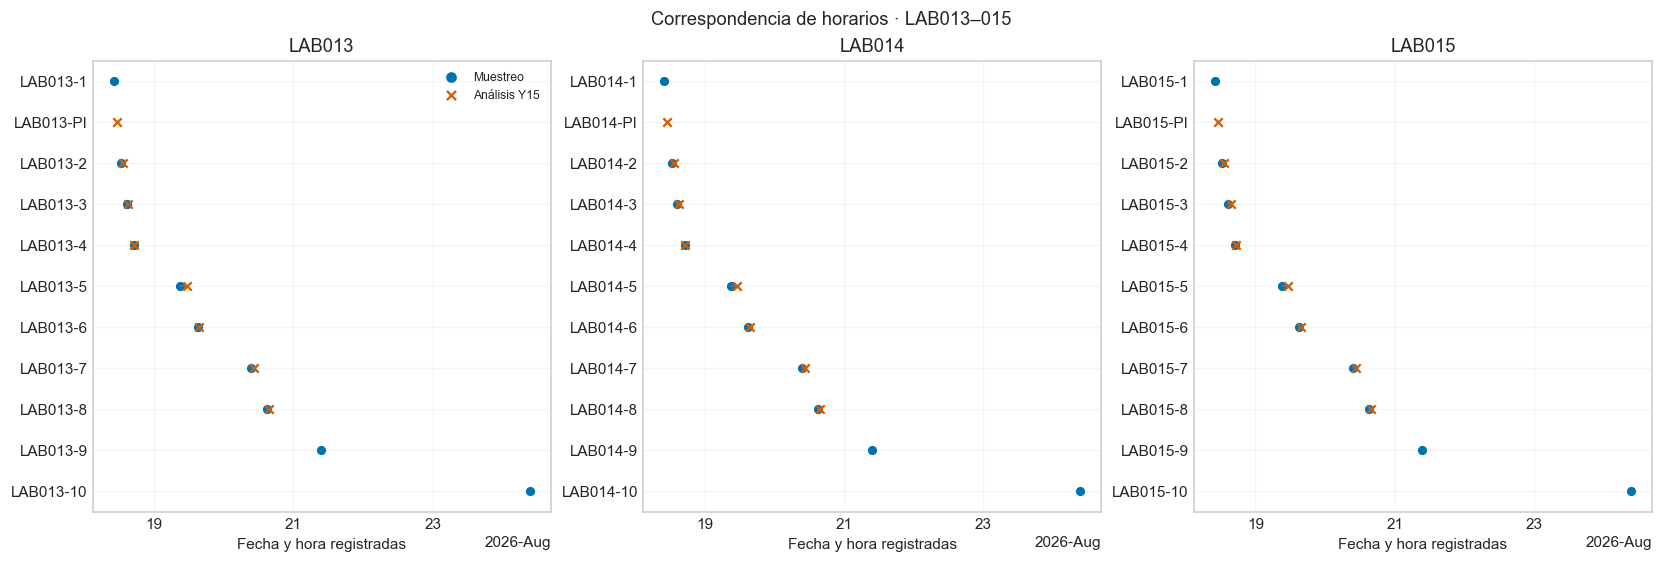

,n,minimo,mediana,maximo
lab_id,,,,
LAB013,7,10.22,37.38,131.15
LAB014,7,12.62,38.18,131.95
LAB015,7,17.42,46.17,134.35


Retrasos negativos: 0
Muestras de planilla sin Y15: ['LAB013-1', 'LAB013-9', 'LAB013-10', 'LAB014-1', 'LAB014-9', 'LAB014-10', 'LAB015-1', 'LAB015-9', 'LAB015-10']
Registros Y15 sin hora de muestreo asociada: ['LAB013-PI', 'LAB014-PI', 'LAB015-PI']


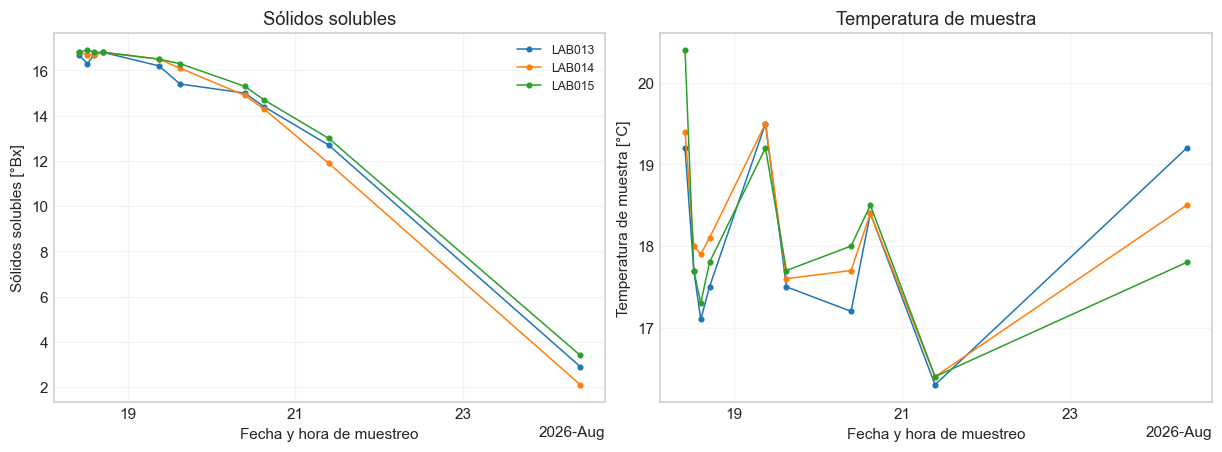

,muestras,primera_hora_Y15,ultima_hora_Y15,YAN_inicial,YAN_final,azucar_inicial,azucar_final
lab_id,,,,,,,
LAB013,7,2026-08-18 13:12:58,2026-08-20 15:37:23,237.0,164.0,146.60,134.95
LAB014,7,2026-08-18 13:13:46,2026-08-20 15:38:11,246.0,146.0,155.80,130.71
LAB015,7,2026-08-18 13:16:10,2026-08-20 15:40:35,250.0,168.0,152.94,137.72


Revisión completada: 24 registros Y15, 30 muestras de planilla y 21 correspondencias exactas por identificador.


In [27]:

fig, axes = plt.subplots(1, 3, figsize=(15, 5), layout='constrained')
for ax, lab in zip(axes, REVIEW_LABS):
    frame = review_joined.loc[review_joined.lab_id.eq(lab)].sort_values('plot_datetime')
    for row, record in enumerate(frame.itertuples()):
        if pd.notna(record.sample_datetime) and pd.notna(record.y15_datetime):
            ax.plot([record.sample_datetime, record.y15_datetime], [row, row], color='#777777', lw=1)
        if pd.notna(record.sample_datetime):
            ax.scatter(record.sample_datetime, row, color='#0072B2', marker='o', s=25)
        if pd.notna(record.y15_datetime):
            ax.scatter(record.y15_datetime, row, color='#D55E00', marker='x', s=30)
    ax.set_yticks(range(len(frame)), frame.sample_id)
    ax.invert_yaxis()
    locator = mdates.AutoDateLocator(minticks=3, maxticks=5)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.set(title=lab, xlabel='Fecha y hora registradas')
    ax.grid(alpha=.2)
axes[0].scatter([], [], color='#0072B2', marker='o', label='Muestreo')
axes[0].scatter([], [], color='#D55E00', marker='x', label='Análisis Y15')
axes[0].legend(fontsize=8)
fig.suptitle('Correspondencia de horarios · LAB013–015')
plt.show()
review_delays = review_joined.loc[review_joined['_merge'].eq('both')].groupby('lab_id').delay_min.agg(n='size', minimo='min', mediana='median', maximo='max')
display(review_delays.round(2))
print('Retrasos negativos:', int(review_joined.delay_min.lt(0).sum()))
print('Muestras de planilla sin Y15:', review_joined.loc[review_joined['_merge'].eq('right_only'), 'sample_id'].tolist())
print('Registros Y15 sin hora de muestreo asociada:', review_joined.loc[review_joined['_merge'].eq('left_only'), 'sample_id'].tolist())
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
for ax, (column, label, unit) in zip(axes, [('brix_degBx','Sólidos solubles','°Bx'), ('temperature_C','Temperatura de muestra','°C')]):
    for lab in REVIEW_LABS:
        frame = review_offline.loc[review_offline.lab_id.eq(lab)].sort_values('sample_datetime')
        ax.plot(frame.sample_datetime, frame[column], 'o-', ms=3, lw=1, label=lab)
    locator = mdates.AutoDateLocator(minticks=3, maxticks=5)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.set(title=label, ylabel=f'{label} [{unit}]', xlabel='Fecha y hora de muestreo')
    ax.grid(alpha=.2)
axes[0].legend(fontsize=8)
plt.show()
review_endpoints = review_y15.loc[review_y15.sample_type.eq('fermentation_sample')].sort_values('y15_datetime').groupby('lab_id').agg(
    muestras=('sample_id','size'), primera_hora_Y15=('y15_datetime','min'), ultima_hora_Y15=('y15_datetime','max'),
    YAN_inicial=('YAN_mg_L','first'), YAN_final=('YAN_mg_L','last'),
    azucar_inicial=('glucose_fructose_g_L','first'), azucar_final=('glucose_fructose_g_L','last'))
with pd.option_context('display.max_columns', None):display(review_endpoints)
assert all(hashlib.sha256(path.read_bytes()).hexdigest() == value for path, value in review_hashes.items())
print('Revisión completada: 24 registros Y15, 30 muestras de planilla y 21 correspondencias exactas por identificador.')


### Densidad medida · LAB013–015

La planilla `All_samples` contiene diez mediciones de densidad por lote. Se presentan la cobertura, las treinta muestras y una matriz con un panel por lote, con la misma escala vertical. La unidad de la planilla es kg/m³, numéricamente equivalente a g/L. Se utiliza la fecha y hora de muestreo registrada.

,mediciones,primera_muestra,ultima_muestra,densidad_inicial,densidad_final
lab_id,,,,,
LAB013,10,2026-08-18 10:00:00,2026-08-24 09:30:00,1066.7,1009.3
LAB014,10,2026-08-18 10:00:00,2026-08-24 09:30:00,1067.1,1006.6
LAB015,10,2026-08-18 10:00:00,2026-08-24 09:30:00,1066.9,1011.7


,sample_id,lab_id,sample_datetime,rho_value,rho_unit,notes
0,LAB013-1,LAB013,2026-08-18 10:00:00,1066.7,kg/m3,NaN
3,LAB013-2,LAB013,2026-08-18 12:30:00,1065.2,kg/m3,NaN
6,LAB013-3,LAB013,2026-08-18 14:30:00,1067.2,kg/m3,NaN
9,LAB013-4,LAB013,2026-08-18 17:00:00,1067.5,kg/m3,NaN
12,LAB013-5,LAB013,2026-08-19 09:00:00,1064.3,kg/m3,NaN
15,LAB013-6,LAB013,2026-08-19 15:00:00,1061.4,kg/m3,NaN
18,LAB013-7,LAB013,2026-08-20 09:30:00,1060.1,kg/m3,NaN
21,LAB013-8,LAB013,2026-08-20 15:00:00,1057.2,kg/m3,NaN
24,LAB013-9,LAB013,2026-08-21 09:30:00,1050.5,kg/m3,NaN
27,LAB013-10,LAB013,2026-08-24 09:30:00,1009.3,kg/m3,NaN


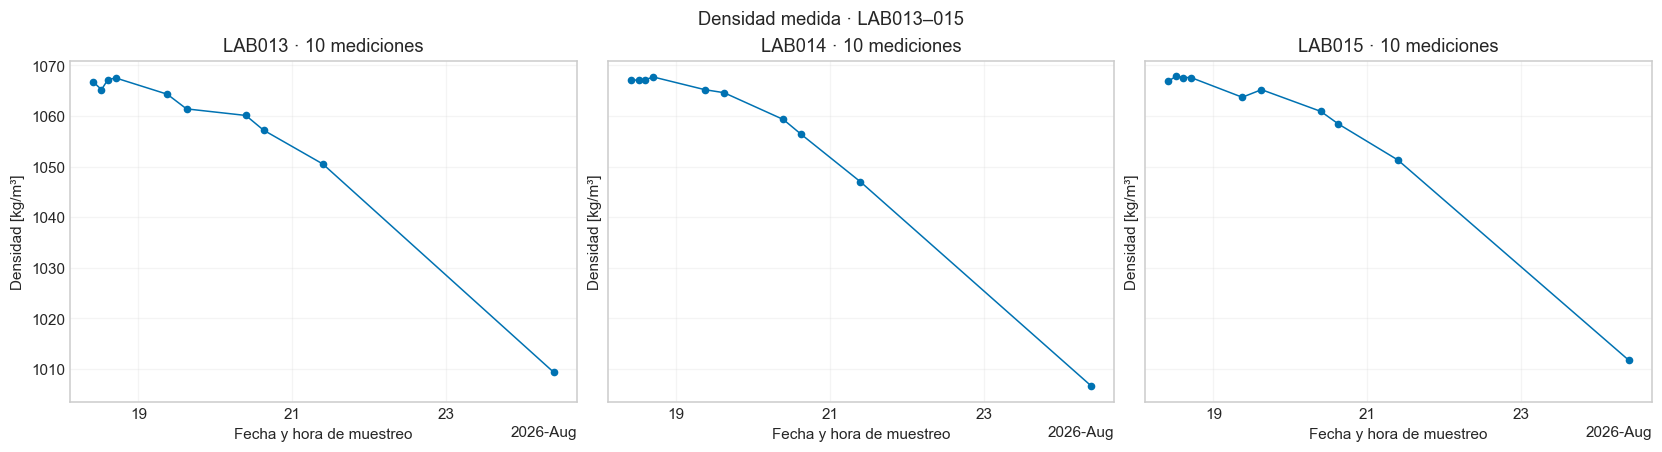

In [28]:

review_density = review_offline[['sample_id', 'lab_id', 'sample_datetime', 'rho_value', 'rho_unit', 'notes']].sort_values(['lab_id', 'sample_datetime']).copy()
review_density['rho_value'] = pd.to_numeric(review_density.rho_value, errors='coerce')
review_density_coverage = review_density.groupby('lab_id').agg(
    mediciones=('rho_value', 'count'), primera_muestra=('sample_datetime', 'min'),
    ultima_muestra=('sample_datetime', 'max'), densidad_inicial=('rho_value', 'first'),
    densidad_final=('rho_value', 'last'))
display(review_density_coverage)
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(review_density)
assert review_density_coverage.mediciones.eq(10).all()
assert review_density.rho_value.notna().all()
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True, layout='constrained')
for ax, lab in zip(axes, REVIEW_LABS):
    frame = review_density.loc[review_density.lab_id.eq(lab)].sort_values('sample_datetime')
    ax.plot(frame.sample_datetime, frame.rho_value, 'o-', color='#0072B2', ms=4, lw=1)
    locator = mdates.AutoDateLocator(minticks=3, maxticks=5)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.set(title=f'{lab} · {frame.rho_value.notna().sum()} mediciones',
           xlabel='Fecha y hora de muestreo', ylabel='Densidad [kg/m³]')
    ax.grid(alpha=.2)
fig.suptitle('Densidad medida · LAB013–015')
plt.show()
assert all(hashlib.sha256(path.read_bytes()).hexdigest() == value for path, value in review_hashes.items())


### Resumen de la revisión de LAB013–015

Cada lote aporta ocho registros Y15, una muestra preinóculo y siete muestras de fermentación. Hay siete valores de fermentación por lote para YAN, glucosa, fructosa, azúcar total, amonio, nitrógeno de aminoácidos primarios y glicerol. Las fuentes tabuladas revisadas no contienen una serie de etanol.

La química Y15 cubre el 18–20 de agosto de 2026. La planilla contiene diez muestras por lote y llega hasta el 24 de agosto. Las muestras 1, 9 y 10 de cada lote carecen de registro Y15 con el mismo identificador. Las tres muestras preinóculo tienen hora de análisis Y15 y carecen de correspondencia exacta de muestreo en la planilla.

| Lote | Mediana del tiempo entre muestreo y análisis [min] | Mayor tiempo entre muestreo y análisis [min] | YAN final medido [mg N/L] | Azúcar total final medido [g/L] |
|---|---:|---:|---:|---:|
| LAB013 | 37,38 | 131,15 | 164 | 134,95 |
| LAB014 |38,18 | 131,95 | 146 | 130,71 |
| LAB015 | 46,17 | 134,35 | 168 | 137,72 |

Las series químicas terminan con nitrógeno y azúcar todavía presentes. Se observan aumentos entre algunas mediciones consecutivas de azúcar y nitrógeno, visibles en los gráficos y conservados para revisar su consistencia. La planilla deja vacío el tiempo desde inoculación. La revisión presenta las fechas registradas y mantiene diferenciadas las horas de muestreo y análisis. La selección de observaciones para calibración se decide después de esta revisión.